# MiBici - Entrega final: reproducibilidad, servicio y monitoreo del modelo
## Objetivo
En las fases anteriores dejamos listo el pipeline: preparación de la demanda diaria, variables, validación temporal, entrenamiento y registro del modelo en MLflow (notebooks 05 y 06). Para la entrega final falta llevar ese modelo a un servicio que otros programas puedan usar, comprobar que da los mismos resultados fuera de nuestro entorno, empaquetarlo en Docker y vigilar qué pasa cuando los datos cambian.

Igual que en el 06, primero probamos todo aquí. Cuando cada sección funcione con los datos reales, pasamos el código a los módulos de `mibici_mlops` y a las pruebas de `tests/`.

El notebook tiene estas secciones:

- Reproducibilidad del modelo. Revisamos versiones, semillas y datos, confirmamos cuál es el modelo registrado y dejamos una copia lista para el despliegue.
- Servicio con FastAPI. Exponemos el modelo con `POST /predict` y probamos que responde lo mismo que el modelo.
- Contenedor Docker. Empaquetamos el servicio, lo probamos desde fuera del contenedor y lo publicamos en DockerHub.
- Data drift. Medimos el cambio en octubre de 2026 real y en tres escenarios sintéticos, definimos alertas con dos niveles y una acción, y registramos todo en MLflow. Como la acción fue reentrenar, comparamos un challenger contra la v7 con un mes para elegir y otro para probar, y mostramos la decisión de promoverlo y cómo se despliega.
- Pruebas. Pasamos las revisiones de las secciones anteriores a pruebas unitarias y de integración con `pytest`.

## Requisitos para ejecutar este notebook
- Abrirlo desde `notebooks/` con el entorno del proyecto activado (`pip install -r requirements.txt`).
- Tener `data/processed/mibici_integrated.parquet` con su manifiesto, `models/mibici_final_model.joblib` y `mlflow.db` en la raíz. No se necesitan los CSV originales.
- Para la sección 3: `fastapi`, `uvicorn` y `httpx` (este último lo usa `TestClient`).
- Para la sección 4: Docker Desktop abierto antes de ejecutar. Esto se configura a mano una sola vez:
  - En Windows con WSL, activar la integración con Ubuntu en Docker Desktop: *Settings > Resources > WSL integration*.
  - Para no tener que abrirlo cada vez: *Settings > General > Start Docker Desktop when you sign in to your computer*.
  - Para comprobarlo, `docker version` en la terminal debe mostrar una sección `Server`. Si dice `failed to connect to the docker API`, Docker no está abierto.
  - Si no se tiene Docker, se puede saltar la sección 4 completa: la sección 5 no la necesita.

## 1. Preparación del entorno
Importamos las librerías y los valores de `config.py`. El notebook busca la raíz del repositorio a partir de la carpeta donde se abre, así las rutas no dependen de la computadora de cada integrante. La conexión a MLflow usa la misma base `mlflow.db` del entrenamiento.

Aquí también está `AUTO_PROMOTE`. Empieza en `False` para que ejecutar el notebook no cambie el modelo que está en producción; la promoción de 5.15 se muestra como simulación.

In [1]:
import hashlib
import json
import platform
import sys
from importlib import metadata
from pathlib import Path

import joblib
import mlflow
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mibici_mlops.config import (
    FEATURE_COLUMNS, FINAL_MODEL_PATH, HORIZON_DAYS, INTEGRATED_PATH, LAGS, MLFLOW_TRACKING_URI,
    MODEL_ALIAS, REFERENCE_RESULTS, REGISTERED_MODEL_NAME, ROLLING_WINDOWS, SEED, TARGET_COLUMN,
    TEST_START,
)
from mibici_mlops.features import build_model_dataset, split_by_date
from mibici_mlops.modeling.evaluate import regression_metrics

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
client = mlflow.MlflowClient()
print("Raíz del proyecto:", ROOT)
print("MLflow:", MLFLOW_TRACKING_URI)

# Con False, la sección 5.15 solo muestra la decisión de promoción y correr el notebook no cambia
# el modelo en producción. Con True registra al challenger y le pasa el alias champion si cumple la regla.
AUTO_PROMOTE = False
print("AUTO_PROMOTE:", AUTO_PROMOTE)

Raíz del proyecto: /home/josel/mlops/equipo-8-mibici-mlops
MLflow: sqlite:////home/josel/mlops/equipo-8-mibici-mlops/mlflow.db
AUTO_PROMOTE: False


## 2. Reproducibilidad del modelo
La entrega pide demostrar que el mismo modelo da los mismos resultados en otro entorno. Antes de llevarlo a otro lado necesitamos saber exactamente qué modelo tenemos, con qué librerías se entrenó y con qué datos.

### 2.1 Versiones del entorno
Estas son las versiones con las que se entrenó el modelo, y las que fijamos en `requirements.txt`. La más importante es `scikit-learn`: el modelo se guarda serializado y otra versión puede no cargarlo o cambiar las predicciones.

In [2]:
PACKAGES = ["scikit-learn", "pandas", "numpy", "scipy", "joblib", "cloudpickle", "pyarrow", "mlflow"]
environment = {"python": platform.python_version()}
for package in PACKAGES:
    try:
        environment[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        environment[package] = None
pd.Series(environment, name="versión").to_frame()

,versión
python,3.13.17
scikit-learn,1.9.1
pandas,3.0.6
numpy,2.5.4
scipy,1.18.1
joblib,1.6.0
cloudpickle,3.1.2
pyarrow,25.0.1
mlflow,3.17.2


### 2.2 Semillas
`SEED = 42` está en `config.py` y se pasa a Random Forest, HistGradientBoosting y TargetEncoder. En lugar de suponerlo, lo leemos directamente del modelo guardado. También confirmamos que el modelo espera las mismas 18 variables, en el mismo orden, que `FEATURE_COLUMNS`.

In [3]:
final_model = joblib.load(FINAL_MODEL_PATH)
seeds = {
    "config.SEED": SEED,
    "RandomForest.random_state": final_model.named_steps["model"].random_state,
    "TargetEncoder.random_state": final_model.named_steps["preprocessing"]
        .named_transformers_["station"].random_state,
}
assert list(final_model.feature_names_in_) == FEATURE_COLUMNS, "Las variables del modelo no coinciden"
pd.Series(seeds, name="valor").to_frame()

,valor
config.SEED,42
RandomForest.random_state,42
TargetEncoder.random_state,42


### 2.3 Versión de los datos
En la Fase 2 guardamos el SHA-256 del Parquet integrado en dos lugares: el manifiesto que está junto al archivo y la procedencia que se registró en MLflow. Si los tres valores coinciden, el dataset que tenemos es el mismo con el que se entrenó.

Después mostramos el inventario de los CSV de origen, con su versión y su hash.

In [4]:
def sha256(path, block=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(block), b""):
            digest.update(chunk)
    return digest.hexdigest()

integrated_sha = sha256(INTEGRATED_PATH)
manifest_path = INTEGRATED_PATH.with_suffix(".manifest.json")
provenance_path = ROOT / "reports" / "mlflow_provenance" / "data_provenance.json"
manifest = json.loads(manifest_path.read_text()) if manifest_path.is_file() else {}
provenance = json.loads(provenance_path.read_text()) if provenance_path.is_file() else {}

pd.DataFrame([
    {"fuente": "actual", "sha256": integrated_sha},
    {"fuente": "manifiesto", "sha256": manifest.get("sha256")},
    {"fuente": "procedencia MLflow", "sha256": provenance.get("integrated_sha256")},
]).assign(coincide=lambda t: t["sha256"] == integrated_sha)

,fuente,sha256,coincide
0,actual,4ddb76fdfe9c0aef5f7cfc7252d85d2df64e31aac98ff9...,True
1,manifiesto,4ddb76fdfe9c0aef5f7cfc7252d85d2df64e31aac98ff9...,True
2,procedencia MLflow,4ddb76fdfe9c0aef5f7cfc7252d85d2df64e31aac98ff9...,True


In [5]:
inventory_path = ROOT / "reports" / "data_versioning" / "all_files" / "file_versions.csv"
if inventory_path.is_file():
    inventory = pd.read_csv(inventory_path)
    display(inventory.head(10))
    print(f"{len(inventory)} archivos inventariados")
else:
    print("No se encontró", inventory_path)

,file,role,stage,sha256,version,size_bytes
0,data/raw/2025/datos_abiertos_2025_06.csv,csv_inventariado,inventario_datos,063e3523db00c90899f08fb134c4c382667eb0e4d8b635...,1,30924814
1,data/raw/2025/datos_abiertos_2025_10.csv,csv_inventariado,inventario_datos,505d9b8b59f65fa223f7889189b74b9fe167c9dda11c7e...,1,36442309
2,data/raw/2025/datos_abiertos_2025_02.csv,csv_inventariado,inventario_datos,f52f13f59eb2f1517e05c72f0a3d3d70c5b0fa6b86626c...,1,32304810
3,data/raw/2025/datos_abiertos_2025_09.csv,csv_inventariado,inventario_datos,218bed1587a70ec5fc5e8589a04783532301f19c55acd3...,1,32686988
4,data/raw/2025/datos_abiertos_2025_03.csv,csv_inventariado,inventario_datos,e5aa1b5d197f294022d3f0ff1b55bf553fcbdb697b50d4...,1,35131572
5,data/raw/2025/datos_abiertos_2025_04.csv,csv_inventariado,inventario_datos,630e637d6611aadc67aad321edcd541361220473bddf8e...,1,31755599
6,data/raw/2025/datos_abiertos_2025_05.csv,csv_inventariado,inventario_datos,e0a744412a1e840c1d24c24269565a123b35739c0bac49...,1,34332994
7,data/raw/2025/datos_abiertos_2025_01.csv,csv_inventariado,inventario_datos,90ee75701a69374926af0400d204f3280baed0e3c1a1f9...,1,32959338
8,data/raw/2025/datos_abiertos_2025_07.csv,csv_inventariado,inventario_datos,a71a9e2a629ff91b021f57e302958e64fa545678d6373a...,1,31932339
9,data/raw/2025/datos_abiertos_2025_11.csv,csv_inventariado,inventario_datos,f5c4f1b0c0842339dfdfaac756607314bdf5b64d17cde5...,1,32997087


205 archivos inventariados


### 2.4 Modelo registrado en MLflow
En el Model Registry hay varias versiones de `mibici_salidas_diarias`. Aquí usamos dos:

- La versión 7, que es la que entregamos en la fase 2 y la que guarda `models/mibici_final_model.joblib`. Es la que reproducimos en esta sección y la que estuvo en uso durante octubre, así que también es la que monitoreamos en la sección 5.
- El alias `champion`, que indica qué versión se despliega. Al inicio de esta entrega apuntaba a la 7. Cuando se promueve un challenger (5.15), el alias pasa a la versión nueva y la exportación de 2.6 la toma.

Citamos los modelos por número de versión, `models:/mibici_salidas_diarias/<versión>`, porque es lo que va en el README y lo que se empaqueta. También mostramos las métricas que quedaron registradas en la ejecución de la versión 7.

In [6]:
versions = client.search_model_versions(f"name='{REGISTERED_MODEL_NAME}'")
registry = pd.DataFrame([{
    "version": int(v.version), "run_id": v.run_id, "aliases": ", ".join(v.aliases),
    "creado": pd.to_datetime(v.creation_timestamp, unit="ms"),
} for v in versions]).sort_values("version")
display(registry)

PHASE2_VERSION = 7   # versión de la fase 2, la que guarda models/mibici_final_model.joblib

phase2 = client.get_model_version(REGISTERED_MODEL_NAME, PHASE2_VERSION)
PHASE2_URI = f"models:/{REGISTERED_MODEL_NAME}/{phase2.version}"
deployed_version = client.get_model_version_by_alias(REGISTERED_MODEL_NAME, MODEL_ALIAS)
run = client.get_run(phase2.run_id)
print("Versión que reproducimos y monitoreamos:", PHASE2_URI, "| run:", phase2.run_id)
print(f"Alias {MODEL_ALIAS} hoy: versión {deployed_version.version}")
pd.Series({k: v for k, v in run.data.metrics.items() if k.startswith(("test", "val", "mae", "rmse"))},
          name="métrica registrada").sort_index().to_frame()

,version,run_id,aliases,creado
9,1,049a7bfb4941479c84a9d553bd2c0605,,2026-11-04 20:09:29.167
8,2,84adca75369a4f0b8703eefb4eee710a,,2026-11-04 21:42:39.710
7,3,a9e63be2fc494bada8c32498c8ab118a,,2026-11-04 23:10:02.120
6,4,01bec77ea684468cb47423d83523163b,,2026-11-05 01:07:05.006
5,5,ed39043036fa4e45b45972b9dc07af95,,2026-11-05 02:10:49.677
4,6,53a89bf48a08461181a284c1bd684b7d,,2026-11-05 03:22:21.274
3,7,cc0940964aeb486c804fa3d378e0bb92,,2026-11-08 02:18:01.370
2,8,6c5f86d661cb4282a0d9b91303de4fe7,,2026-11-17 23:00:45.965
1,9,814f33a5161148de84d5ab66875f6bb3,,2026-11-17 23:10:55.362
0,10,19bba2e18fe94053978b24cf272864a6,,2026-11-17 23:53:12.692


Versión que reproducimos y monitoreamos: models:/mibici_salidas_diarias/7 | run: cc0940964aeb486c804fa3d378e0bb92
Alias champion hoy: versión 10


,métrica registrada
test_known_mae,6.107525
test_known_naive_mae,8.100579
test_known_rmse,11.142441
test_known_rows,99487.000000
test_known_skill_vs_naive,0.246038
test_mae,5.896360
test_naive_mae,7.956580
test_new_mae,3.510964
test_new_naive_mae,6.329924
test_new_rmse,5.205644


### 2.5 Mismo modelo, mismos resultados
Hacemos dos comparaciones con la prueba completa de 2026:

1. El `.joblib` que guarda `train.py` y el modelo del Registry deberían ser el mismo. Comparamos sus predicciones fila por fila.
2. Recalculamos MAE y RMSE y los comparamos con los del README y MLflow.

Con `n_jobs=-1` los árboles se promedian en paralelo y el orden de la suma puede cambiar, así que esperamos diferencias del orden de 1e-13, no ceros exactos.

In [7]:
integrated = pd.read_parquet(INTEGRATED_PATH)
dataset = build_model_dataset(integrated, HORIZON_DAYS, LAGS, ROLLING_WINDOWS, TARGET_COLUMN)
development, test = split_by_date(dataset, TEST_START)
print(f"Prueba: {len(test):,} filas, {test['Fecha'].min().date()} a {test['Fecha'].max().date()}")

phase2_model = mlflow.sklearn.load_model(PHASE2_URI)
pred_joblib = final_model.predict(test[FEATURE_COLUMNS])
pred_phase2 = phase2_model.predict(test[FEATURE_COLUMNS])
print("Diferencia máxima joblib vs v7 del registro:", float(np.abs(pred_joblib - pred_phase2).max()))

Prueba: 108,294 filas, 2026-01-01 a 2026-09-30
Diferencia máxima joblib vs v7 del registro: 1.4210854715202004e-13


In [8]:
test_metrics = regression_metrics(test[TARGET_COLUMN], pred_phase2)
reference_mae = REFERENCE_RESULTS["Modelo final, prueba 2026 (todas)"]
comparison = pd.DataFrame([
    {"métrica": "MAE prueba 2026", "referencia": reference_mae, "actual": test_metrics["mae"]},
    {"métrica": "RMSE prueba 2026", "referencia": 10.7824, "actual": test_metrics["rmse"]},
])
comparison["diferencia"] = (comparison["actual"] - comparison["referencia"]).abs()
comparison.round(4)

,métrica,referencia,actual,diferencia
0,MAE prueba 2026,5.8960,5.8964,0.0004
1,RMSE prueba 2026,10.7824,10.7824,0.0000


### 2.6 Artefactos para el despliegue
Copiamos el modelo que tiene el alias `champion` a `models/serving/model` sin volver a serializarlo, para que el servicio y Docker usen exactamente el mismo binario. Junto a él guardamos:

- `metadata.json`: nombre, versión, ejecución, variables, semilla, hash del dataset y versiones del entorno.
- `reference_sample.csv`: 500 filas fijas de la prueba 2026 con la predicción del modelo exportado. Es la referencia que volveremos a predecir en la API y dentro del contenedor.

Lo dejamos en una función porque se vuelve a usar en 5.16 cuando cambia el champion. El binario no se sube a Git; vive en MLflow y en la imagen de Docker.

In [9]:
import shutil
from datetime import datetime, timezone

SERVING_DIR = ROOT / "models" / "serving"


def export_serving_model(version) -> pd.DataFrame:
    uri = f"models:/{REGISTERED_MODEL_NAME}/{version.version}"
    model_dir = SERVING_DIR / "model"
    if model_dir.exists():
        shutil.rmtree(model_dir)
    model_dir.mkdir(parents=True)
    downloaded = Path(mlflow.artifacts.download_artifacts(artifact_uri=uri, dst_path=str(model_dir)))
    if downloaded.resolve() != model_dir.resolve():
        for item in downloaded.iterdir():
            shutil.move(str(item), model_dir / item.name)
        shutil.rmtree(downloaded)

    metadata_info = {
        "model_name": REGISTERED_MODEL_NAME,
        "model_version": str(version.version),
        "model_alias": MODEL_ALIAS,
        "registry_uri": uri,
        "run_id": version.run_id,
        "features": FEATURE_COLUMNS,
        "seed": SEED,
        "integrated_sha256": integrated_sha,
        "environment": environment,
        "exported_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }
    (SERVING_DIR / "metadata.json").write_text(json.dumps(metadata_info, indent=2, ensure_ascii=False))

    served_model = mlflow.sklearn.load_model(str(model_dir))
    sample = test.sample(n=min(500, len(test)), random_state=SEED).sort_values(["Fecha", "Origen_Id"])
    reference = sample[["Fecha"] + FEATURE_COLUMNS + [TARGET_COLUMN]].copy()
    reference["reference_prediction"] = served_model.predict(sample[FEATURE_COLUMNS])
    reference.to_csv(SERVING_DIR / "reference_sample.csv", index=False)
    print(f"Exportado {uri} a {model_dir}")
    return reference


reference = export_serving_model(deployed_version)
print(sorted(p.name for p in (SERVING_DIR / "model").iterdir()))
print("Requirements que MLflow guardó con el modelo:")
print((SERVING_DIR / "model" / "requirements.txt").read_text())

Exportado models:/mibici_salidas_diarias/10 a /home/josel/mlops/equipo-8-mibici-mlops/models/serving/model
['MLmodel', 'conda.yaml', 'input_example.json', 'model.pkl', 'python_env.yaml', 'registered_model_meta', 'requirements.txt', 'serving_input_example.json']
Requirements que MLflow guardó con el modelo:
mlflow==3.17.2
cloudpickle==3.1.2
numpy==2.5.4
pandas==3.0.6
psutil==7.2.2
rich==15.0.0
scikit-learn==1.9.1
scipy==1.18.1


## 3. Servicio de predicción con FastAPI
Con el modelo identificado, lo exponemos como servicio para que otro programa pueda pedir predicciones sin abrir notebooks.

Una decisión importante es qué recibe el servicio. El modelo usa la historia reciente de cada estación (`lag_1`, `lag_7`, `roll_mean_28`, etc.), y la API no guarda los viajes. Por eso quien llama manda una fila por estación y día con las 18 variables ya calculadas. Para una estación nueva los rezagos pueden ir vacíos (`null`), y el imputador del pipeline los trata igual que en el entrenamiento.

### 3.1 Esquema de entrada y salida
Con Pydantic describimos cada variable con su tipo y su rango válido: el día de la semana va de 0 a 6, el mes de 1 a 12 y los conteos no pueden ser negativos. `extra="forbid"` rechaza variables que el modelo no conoce. Al final comprobamos que el esquema tiene las mismas variables que el modelo, en el mismo orden.

In [10]:
from contextlib import asynccontextmanager

from fastapi import FastAPI, HTTPException, Request
from fastapi.testclient import TestClient
from pydantic import BaseModel, ConfigDict, Field

API_VERSION = "1.0.0"
MAX_INSTANCES = 5_000

EXAMPLE_INSTANCE = {
    "Origen_Id": 35, "day_of_week": 2, "month": 10, "day_of_month": 15, "weather_zone": 3,
    "education_count": 4, "transport_count": 1, "commerce_count": 2, "work_count": 6,
    "health_count": 0, "recreation_count": 3,
    "lag_1": 41, "lag_7": 38, "lag_14": 36, "roll_mean_7": 39.4, "active_days_7": 7,
    "roll_mean_28": 37.9, "active_days_28": 28,
}


class StationDayFeatures(BaseModel):
    """Las 18 variables del modelo para una estación y un día."""

    model_config = ConfigDict(extra="forbid", json_schema_extra={"example": EXAMPLE_INSTANCE})

    Origen_Id: int = Field(..., gt=0, description="Id de la estación de origen")
    day_of_week: int = Field(..., ge=0, le=6, description="0 = lunes, 6 = domingo")
    month: int = Field(..., ge=1, le=12)
    day_of_month: int = Field(..., ge=1, le=31)
    weather_zone: int = Field(..., ge=0, description="Zona meteorológica de la estación")
    education_count: int = Field(..., ge=0, description="POI de educación a 500 m")
    transport_count: int = Field(..., ge=0, description="POI de transporte a 500 m")
    commerce_count: int = Field(..., ge=0, description="POI de comercio a 500 m")
    work_count: int = Field(..., ge=0, description="POI de oficinas a 500 m")
    health_count: int = Field(..., ge=0, description="POI de salud a 500 m")
    recreation_count: int = Field(..., ge=0, description="POI de recreación a 500 m")
    lag_1: float | None = Field(None, ge=0, description="Salidas del día anterior")
    lag_7: float | None = Field(None, ge=0, description="Salidas de hace 7 días")
    lag_14: float | None = Field(None, ge=0, description="Salidas de hace 14 días")
    roll_mean_7: float | None = Field(None, ge=0, description="Promedio de los últimos 7 días")
    active_days_7: int = Field(..., ge=0, le=7, description="Días con registro en los últimos 7")
    roll_mean_28: float | None = Field(None, ge=0, description="Promedio de los últimos 28 días")
    active_days_28: int = Field(..., ge=0, le=28, description="Días con registro en los últimos 28")


class PredictRequest(BaseModel):
    model_config = ConfigDict(extra="forbid",
                              json_schema_extra={"example": {"instances": [EXAMPLE_INSTANCE]}})
    instances: list[StationDayFeatures] = Field(..., min_length=1, max_length=MAX_INSTANCES)


class Prediction(BaseModel):
    Origen_Id: int
    predicted_trips: float = Field(..., description="Viajes que inician en la estación ese día")


class PredictResponse(BaseModel):
    model_name: str
    model_version: str
    model_uri: str
    predictions: list[Prediction]


class HealthResponse(BaseModel):
    status: str
    model_loaded: bool
    model_name: str | None = None
    model_version: str | None = None


# Las variables del esquema deben ser exactamente las del modelo, en el mismo orden.
assert list(StationDayFeatures.model_fields) == FEATURE_COLUMNS
StationDayFeatures(**EXAMPLE_INSTANCE)
print("Esquema válido:", len(StationDayFeatures.model_fields), "variables")

Esquema válido: 18 variables


/home/josel/mlops/equipo-8-mibici-mlops/.venv/lib/python3.13/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


### 3.2 Carga del modelo
El servicio carga la copia de `models/serving/model` y lee su `metadata.json` para responder con el nombre y la versión. Las predicciones se recortan en cero porque un número de viajes no puede ser negativo.

In [11]:
MODEL_URI = str(ROOT / "models" / "serving" / "model")


class LoadedModel:
    def __init__(self, uri: str):
        self.uri = uri
        self.model = mlflow.sklearn.load_model(uri)
        meta_path = Path(uri).parent / "metadata.json"
        meta = json.loads(meta_path.read_text()) if meta_path.is_file() else {}
        self.name = meta.get("model_name", REGISTERED_MODEL_NAME)
        self.version = str(meta.get("model_version", "desconocida"))

    def predict(self, features: pd.DataFrame) -> np.ndarray:
        return np.clip(self.model.predict(features[FEATURE_COLUMNS]), 0, None)


served = LoadedModel(MODEL_URI)
print(served.name, "versión", served.version, "|", served.uri)

mibici_salidas_diarias versión 10 | /home/josel/mlops/equipo-8-mibici-mlops/models/serving/model


### 3.3 Aplicación
Usamos una función `create_app` para poder crear el servicio con distintos modelos; la usamos más abajo para probar qué pasa si el modelo no existe. El servicio tiene dos rutas:

- `GET /health` indica si el modelo está cargado y cuál es su versión.
- `POST /predict` recibe las filas y devuelve los viajes estimados por estación.

El modelo se carga una vez, al iniciar. Si falla, el servicio arranca de todos modos: `/health` lo informa y `/predict` responde 503. Las entradas que no cumplen el esquema las rechaza Pydantic con 422.

In [12]:
def create_app(model_uri: str) -> FastAPI:
    @asynccontextmanager
    async def lifespan(app: FastAPI):
        # El modelo se carga una sola vez al iniciar. Si falla, el servicio arranca y /health lo dice.
        try:
            app.state.model = LoadedModel(model_uri)
        except Exception as error:  # noqa: BLE001
            app.state.model, app.state.model_error = None, str(error)
        yield

    app = FastAPI(
        title="MiBici · Predicción de salidas diarias por estación",
        description="Equipo 8, MLOps. Viajes que iniciarán en cada estación el día siguiente.",
        version=API_VERSION,
        lifespan=lifespan,
    )

    @app.get("/health", response_model=HealthResponse, tags=["monitoreo"])
    def health(request: Request) -> HealthResponse:
        model = getattr(request.app.state, "model", None)
        return HealthResponse(status="ok" if model else "degradado", model_loaded=model is not None,
                              model_name=getattr(model, "name", None),
                              model_version=getattr(model, "version", None))

    @app.post("/predict", response_model=PredictResponse, tags=["predicción"])
    def predict(payload: PredictRequest, request: Request) -> PredictResponse:
        model = getattr(request.app.state, "model", None)
        if model is None:
            raise HTTPException(503, f"Modelo no disponible: {request.app.state.model_error}")
        features = pd.DataFrame([row.model_dump() for row in payload.instances])
        history = [c for c in features if c.startswith(("lag_", "roll_"))]
        features[history] = features[history].astype("float64")  # los null pasan a NaN para que los tome el imputador
        try:
            predictions = model.predict(features)
        except Exception as error:  # noqa: BLE001
            raise HTTPException(500, "Error interno al predecir") from error
        return PredictResponse(
            model_name=model.name, model_version=model.version, model_uri=model.uri,
            predictions=[Prediction(Origen_Id=int(s), predicted_trips=round(float(p), 4))
                         for s, p in zip(features["Origen_Id"], predictions)],
        )

    return app


app = create_app(MODEL_URI)
print([route.path for route in app.routes])

['/openapi.json', '/docs', '/docs/oauth2-redirect', '/redoc', '/health', '/predict']


### 3.4 Prueba con un ejemplo
`TestClient` permite llamar al servicio desde el notebook sin levantar un servidor. Probamos `/health` y una predicción con el ejemplo del esquema.

In [13]:
with TestClient(app) as client:
    health_response = client.get("/health")
    example_response = client.post("/predict", json={"instances": [EXAMPLE_INSTANCE]})

print("GET /health:", health_response.status_code, health_response.json())
print("POST /predict:", example_response.status_code)
example_response.json()

GET /health: 200 {'status': 'ok', 'model_loaded': True, 'model_name': 'mibici_salidas_diarias', 'model_version': '10'}
POST /predict: 200


{'model_name': 'mibici_salidas_diarias',
 'model_version': '10',
 'model_uri': '/home/josel/mlops/equipo-8-mibici-mlops/models/serving/model',
 'predictions': [{'Origen_Id': 35, 'predicted_trips': 43.4335}]}

### 3.5 Comparación con el modelo
Mandamos las 500 filas de `reference_sample.csv` y comparamos la respuesta con la predicción guardada en la sección 2.6. La API redondea a cuatro decimales, así que la diferencia debería quedar por debajo de 1e-4.

In [14]:
def to_instance(row: dict) -> dict:
    instance = {}
    for column in FEATURE_COLUMNS:
        value = row[column]
        if pd.isna(value):
            instance[column] = None
        elif column.startswith(("lag_", "roll_")):
            instance[column] = float(value)
        else:
            instance[column] = int(value)
    return instance


reference = pd.read_csv(ROOT / "models" / "serving" / "reference_sample.csv", parse_dates=["Fecha"])
payload = {"instances": [to_instance(r) for r in reference.to_dict(orient="records")]}
with TestClient(app) as client:
    response = client.post("/predict", json=payload)

api_predictions = np.array([p["predicted_trips"] for p in response.json()["predictions"]])
difference = np.abs(api_predictions - reference["reference_prediction"].clip(lower=0).to_numpy())
print("Status:", response.status_code, "| filas:", len(api_predictions))
print("Diferencia máxima API vs modelo:", float(difference.max()))
print("MAE de la muestra (API):", round(regression_metrics(reference[TARGET_COLUMN], api_predictions)["mae"], 4))
assert difference.max() < 1e-4

Status: 200 | filas: 500
Diferencia máxima API vs modelo: 4.9839406344176496e-05
MAE de la muestra (API): 6.3881


### 3.6 Estaciones nuevas
Una estación sin historia llega con los rezagos vacíos. El servicio debe responder sin error.

In [15]:
new_station = {**EXAMPLE_INSTANCE, "Origen_Id": 9999, "lag_1": None, "lag_7": None, "lag_14": None,
               "roll_mean_7": None, "roll_mean_28": None, "active_days_7": 0, "active_days_28": 0}
with TestClient(app) as client:
    response = client.post("/predict", json={"instances": [new_station]})
print(response.status_code, response.json()["predictions"])

200 [{'Origen_Id': 9999, 'predicted_trips': 11.5079}]


### 3.7 Entradas incorrectas
Revisamos que cada entrada incorrecta reciba el código que corresponde y un mensaje que explique el problema. También creamos un servicio con una ruta de modelo que no existe para comprobar la respuesta 503. Estos casos pasarán después a `tests/test_api.py`.

In [16]:
without_month = {k: v for k, v in EXAMPLE_INSTANCE.items() if k != "month"}
cases = [
    ("Día de la semana fuera de rango", {"instances": [{**EXAMPLE_INSTANCE, "day_of_week": 7}]}, 422),
    ("Mes 13", {"instances": [{**EXAMPLE_INSTANCE, "month": 13}]}, 422),
    ("Rezago negativo", {"instances": [{**EXAMPLE_INSTANCE, "lag_1": -3}]}, 422),
    ("Estación como texto", {"instances": [{**EXAMPLE_INSTANCE, "Origen_Id": "centro"}]}, 422),
    ("Variable de más", {"instances": [{**EXAMPLE_INSTANCE, "temperatura": 25}]}, 422),
    ("Falta una variable", {"instances": [without_month]}, 422),
    ("Lista vacía", {"instances": []}, 422),
    ("Cuerpo sin 'instances'", EXAMPLE_INSTANCE, 422),
]
rows = []
with TestClient(app) as client:
    for name, body, expected in cases:
        response = client.post("/predict", json=body)
        detail = response.json()["detail"]
        rows.append({"caso": name, "esperado": expected, "obtenido": response.status_code,
                     "mensaje": detail[0]["msg"] if isinstance(detail, list) else detail})

# Servicio sin modelo: arranca, /health lo informa y /predict responde 503
broken_app = create_app(str(ROOT / "models" / "no_existe"))
with TestClient(broken_app) as client:
    rows.append({"caso": "Health sin modelo", "esperado": 200,
                 "obtenido": client.get("/health").status_code,
                 "mensaje": str(client.get("/health").json())})
    response = client.post("/predict", json={"instances": [EXAMPLE_INSTANCE]})
    rows.append({"caso": "Predict sin modelo", "esperado": 503, "obtenido": response.status_code,
                 "mensaje": response.json()["detail"][:80]})

errors = pd.DataFrame(rows)
errors["ok"] = errors["esperado"] == errors["obtenido"]
assert errors["ok"].all()
errors

,caso,esperado,obtenido,mensaje,ok
0,Día de la semana fuera de rango,422,422,Input should be less than or equal to 6,True
1,Mes 13,422,422,Input should be less than or equal to 12,True
2,Rezago negativo,422,422,Input should be greater than or equal to 0,True
3,Estación como texto,422,422,"Input should be a valid integer, unable to par...",True
4,Variable de más,422,422,Extra inputs are not permitted,True
5,Falta una variable,422,422,Field required,True
6,Lista vacía,422,422,List should have at least 1 item after validat...,True
7,Cuerpo sin 'instances',422,422,Field required,True
8,Health sin modelo,200,200,"{'status': 'degradado', 'model_loaded': False,...",True
9,Predict sin modelo,503,503,Modelo no disponible: No such artifact: 'no_ex...,True


### 3.8 Documentación del servicio
FastAPI genera la documentación OpenAPI a partir de los esquemas. La guardamos en `reports/api/openapi.json` para el repositorio y el reporte. Con el servidor en marcha también se puede consultar en `/docs` (Swagger) y `/redoc`.

In [17]:
openapi = app.openapi()
api_dir = ROOT / "reports" / "api"
api_dir.mkdir(parents=True, exist_ok=True)
(api_dir / "openapi.json").write_text(json.dumps(openapi, indent=2, ensure_ascii=False))
print("Rutas documentadas:", list(openapi["paths"]))
print("Esquemas:", list(openapi["components"]["schemas"]))

Rutas documentadas: ['/health', '/predict']
Esquemas: ['HTTPValidationError', 'HealthResponse', 'PredictRequest', 'PredictResponse', 'Prediction', 'StationDayFeatures', 'ValidationError']


### 3.9 Servidor local (opcional)
Para ver Swagger en el navegador, levantamos Uvicorn en segundo plano. Con el servidor en marcha se abre <http://localhost:8000/docs>, se prueba `POST /predict` con *Try it out* y se toma la captura para el reporte. La celda siguiente lo detiene; hay que ejecutarla antes de la sección 4, porque el contenedor usa el mismo puerto.

In [18]:
import threading
import time

import requests
import uvicorn

server = uvicorn.Server(uvicorn.Config(app, host="127.0.0.1", port=8000, log_level="warning"))
thread = threading.Thread(target=server.run, daemon=True)
thread.start()
time.sleep(3)
print(requests.get("http://127.0.0.1:8000/health", timeout=5).json())
print(requests.post("http://127.0.0.1:8000/predict", json={"instances": [EXAMPLE_INSTANCE]}, timeout=5).json())
print("Swagger: http://localhost:8000/docs")

{'status': 'ok', 'model_loaded': True, 'model_name': 'mibici_salidas_diarias', 'model_version': '10'}
{'model_name': 'mibici_salidas_diarias', 'model_version': '10', 'model_uri': '/home/josel/mlops/equipo-8-mibici-mlops/models/serving/model', 'predictions': [{'Origen_Id': 35, 'predicted_trips': 43.4335}]}
Swagger: http://localhost:8000/docs


In [19]:
server.should_exit = True
thread.join(timeout=5)
print("Servidor detenido")

Servidor detenido


## 4. Contenedor Docker
En la sección 3 el servicio corre dentro de nuestro entorno de Python. Para que funcione igual en cualquier computadora lo empaquetamos en una imagen de Docker con el modelo, el código del servicio y sus librerías.

Como todavía no pasamos el código a los módulos, armamos la imagen en una carpeta aparte, `build/docker/`, con un `app.py` que reúne lo de la sección 3. Cuando pasemos todo a archivos, el `Dockerfile` quedará en la raíz y la imagen se construirá con `docker build -t ml-service:latest .`.

Antes de ejecutar esta sección, Docker Desktop (o Docker en WSL) tiene que estar abierto. Se puede revisar con `docker version` en la terminal.

Definimos los nombres que usamos en toda la sección y una función `run` para ejecutar comandos de Docker y ver su salida.

In [20]:
import os
import shutil
import subprocess
import time

import requests

DOCKER_DIR = ROOT / "build" / "docker"
IMAGE = "ml-service:latest"
CONTAINER = "mibici-api"
DOCKERHUB_REPO = "josecval/mibici-ml-service"
# Una etiqueta fija por cada modelo desplegado. Un champion nuevo recibe la siguiente
# etiqueta menor automáticamente (1.1.0, 1.2.0, ...).
RELEASES = {"7": "1.0.0"}
SERVED_VERSION = json.loads((ROOT / "models" / "serving" / "metadata.json").read_text())["model_version"]
IMAGE_TAG = RELEASES.get(SERVED_VERSION, f"1.{len(RELEASES)}.0")
PORT = 8000


def run(command: list[str], check: bool = True) -> str:
    """Ejecutar un comando y mostrar su salida."""
    print("$", " ".join(command))
    result = subprocess.run(command, capture_output=True, text=True)
    output = (result.stdout + result.stderr).strip()
    if result.returncode != 0 and check:
        print(output[-3000:])
        raise RuntimeError(f"Falló: {' '.join(command)}")
    return output


docker_version = run(["docker", "version", "--format", "Cliente {{.Client.Version}} | Servidor {{.Server.Version}}"],
                     check=False)
print(docker_version)
if "failed to connect" in docker_version or "Cannot connect" in docker_version:
    raise RuntimeError("Docker no está abierto. Abre Docker Desktop y vuelve a correr esta celda, "
                       "o salta a la sección 5, que no necesita Docker.")
if DOCKER_DIR.exists():
    shutil.rmtree(DOCKER_DIR)
(DOCKER_DIR / "models").mkdir(parents=True)
print("Carpeta de construcción:", DOCKER_DIR)
print(f"Modelo en models/serving: versión {SERVED_VERSION}, etiqueta {IMAGE_TAG}")

$ docker version --format Cliente {{.Client.Version}} | Servidor {{.Server.Version}}
Cliente 29.9.3 | Servidor 29.9.3
Carpeta de construcción: /home/josel/mlops/equipo-8-mibici-mlops/build/docker
Modelo en models/serving: versión 10, etiqueta 1.1.0


### 4.1 Código del servicio
`app.py` tiene los esquemas, la carga del modelo y las rutas de la sección 3. La única diferencia es que no importa nada de `mibici_mlops`: la lista de variables la lee de `metadata.json`. Así la imagen solo necesita el modelo y las librerías de inferencia.

In [21]:
%%writefile ../build/docker/app.py
"""API de predicción de salidas diarias por estación de MiBici (Equipo 8)."""

from contextlib import asynccontextmanager
import json
import os
from pathlib import Path

from fastapi import FastAPI, HTTPException, Request
import mlflow.sklearn
import numpy as np
import pandas as pd
from pydantic import BaseModel, ConfigDict, Field

API_VERSION = "1.0.0"
MAX_INSTANCES = 5_000
MODEL_URI = os.getenv("MODEL_URI", "/app/models/serving/model")

EXAMPLE_INSTANCE = {
    "Origen_Id": 35, "day_of_week": 2, "month": 10, "day_of_month": 15, "weather_zone": 3,
    "education_count": 4, "transport_count": 1, "commerce_count": 2, "work_count": 6,
    "health_count": 0, "recreation_count": 3,
    "lag_1": 41, "lag_7": 38, "lag_14": 36, "roll_mean_7": 39.4, "active_days_7": 7,
    "roll_mean_28": 37.9, "active_days_28": 28,
}


class StationDayFeatures(BaseModel):
    """Las 18 variables del modelo para una estación y un día."""

    model_config = ConfigDict(extra="forbid", json_schema_extra={"example": EXAMPLE_INSTANCE})

    Origen_Id: int = Field(..., gt=0, description="Id de la estación de origen")
    day_of_week: int = Field(..., ge=0, le=6, description="0 = lunes, 6 = domingo")
    month: int = Field(..., ge=1, le=12)
    day_of_month: int = Field(..., ge=1, le=31)
    weather_zone: int = Field(..., ge=0, description="Zona meteorológica de la estación")
    education_count: int = Field(..., ge=0, description="POI de educación a 500 m")
    transport_count: int = Field(..., ge=0, description="POI de transporte a 500 m")
    commerce_count: int = Field(..., ge=0, description="POI de comercio a 500 m")
    work_count: int = Field(..., ge=0, description="POI de oficinas a 500 m")
    health_count: int = Field(..., ge=0, description="POI de salud a 500 m")
    recreation_count: int = Field(..., ge=0, description="POI de recreación a 500 m")
    lag_1: float | None = Field(None, ge=0, description="Salidas del día anterior")
    lag_7: float | None = Field(None, ge=0, description="Salidas de hace 7 días")
    lag_14: float | None = Field(None, ge=0, description="Salidas de hace 14 días")
    roll_mean_7: float | None = Field(None, ge=0, description="Promedio de los últimos 7 días")
    active_days_7: int = Field(..., ge=0, le=7, description="Días con registro en los últimos 7")
    roll_mean_28: float | None = Field(None, ge=0, description="Promedio de los últimos 28 días")
    active_days_28: int = Field(..., ge=0, le=28, description="Días con registro en los últimos 28")


class PredictRequest(BaseModel):
    model_config = ConfigDict(extra="forbid",
                              json_schema_extra={"example": {"instances": [EXAMPLE_INSTANCE]}})
    instances: list[StationDayFeatures] = Field(..., min_length=1, max_length=MAX_INSTANCES)


class Prediction(BaseModel):
    Origen_Id: int
    predicted_trips: float = Field(..., description="Viajes que inician en la estación ese día")


class PredictResponse(BaseModel):
    model_name: str
    model_version: str
    model_uri: str
    predictions: list[Prediction]


class HealthResponse(BaseModel):
    status: str
    model_loaded: bool
    model_name: str | None = None
    model_version: str | None = None


class LoadedModel:
    def __init__(self, uri: str):
        self.uri = uri
        self.model = mlflow.sklearn.load_model(uri)
        meta_path = Path(uri).parent / "metadata.json"
        meta = json.loads(meta_path.read_text()) if meta_path.is_file() else {}
        self.name = meta.get("model_name", "mibici_salidas_diarias")
        self.version = str(meta.get("model_version", "desconocida"))
        self.features = meta.get("features") or list(self.model.feature_names_in_)

    def predict(self, features: pd.DataFrame) -> np.ndarray:
        return np.clip(self.model.predict(features[self.features]), 0, None)


@asynccontextmanager
async def lifespan(app: FastAPI):
    try:
        app.state.model = LoadedModel(MODEL_URI)
    except Exception as error:  # noqa: BLE001
        app.state.model, app.state.model_error = None, str(error)
    yield


app = FastAPI(
    title="MiBici · Predicción de salidas diarias por estación",
    description="Equipo 8, MLOps. Viajes que iniciarán en cada estación el día siguiente.",
    version=API_VERSION,
    lifespan=lifespan,
)


@app.get("/health", response_model=HealthResponse, tags=["monitoreo"])
def health(request: Request) -> HealthResponse:
    model = getattr(request.app.state, "model", None)
    return HealthResponse(status="ok" if model else "degradado", model_loaded=model is not None,
                          model_name=getattr(model, "name", None),
                          model_version=getattr(model, "version", None))


@app.post("/predict", response_model=PredictResponse, tags=["predicción"])
def predict(payload: PredictRequest, request: Request) -> PredictResponse:
    model = getattr(request.app.state, "model", None)
    if model is None:
        raise HTTPException(503, f"Modelo no disponible: {request.app.state.model_error}")
    features = pd.DataFrame([row.model_dump() for row in payload.instances])
    history = [c for c in features if c.startswith(("lag_", "roll_"))]
    features[history] = features[history].astype("float64")
    try:
        predictions = model.predict(features)
    except Exception as error:  # noqa: BLE001
        raise HTTPException(500, "Error interno al predecir") from error
    return PredictResponse(
        model_name=model.name, model_version=model.version, model_uri=model.uri,
        predictions=[Prediction(Origen_Id=int(s), predicted_trips=round(float(p), 4))
                     for s, p in zip(features["Origen_Id"], predictions)],
    )

Writing ../build/docker/app.py


### 4.2 Librerías de la imagen
La imagen solo instala lo que se necesita para predecir. Usamos `mlflow-skinny` en lugar de `mlflow` completo porque solo hace falta para cargar el modelo y pesa mucho menos.

Las versiones son las del entrenamiento. Para no equivocarnos, las comparamos con el `requirements.txt` que MLflow guardó junto al modelo.

In [22]:
SERVING_REQUIREMENTS = """\
numpy==2.5.4
pandas==3.0.6
scikit-learn==1.9.1
scipy==1.18.1
joblib==1.6.0
cloudpickle==3.1.2
mlflow-skinny==3.17.2
fastapi==0.158.1
uvicorn==0.54.0
pydantic==2.14.1
"""
(DOCKER_DIR / "requirements.txt").write_text(SERVING_REQUIREMENTS)

# Las versiones de la imagen deben coincidir con las que MLflow guardó junto al modelo.
model_requirements = dict(
    line.split("==") for line in
    (ROOT / "models" / "serving" / "model" / "requirements.txt").read_text().split()
    if "==" in line
)
image_requirements = dict(line.split("==") for line in SERVING_REQUIREMENTS.split())
check = pd.DataFrame([
    {"paquete": p, "modelo (MLflow)": model_requirements.get(p),
     "imagen": image_requirements.get(p if p != "mlflow" else "mlflow-skinny")}
    for p in ["scikit-learn", "pandas", "numpy", "scipy", "cloudpickle", "mlflow"]
])
check["coincide"] = check["modelo (MLflow)"] == check["imagen"]
assert check["coincide"].all(), "La imagen no usa las versiones del entrenamiento"
check

,paquete,modelo (MLflow),imagen,coincide
0,scikit-learn,1.9.1,1.9.1,True
1,pandas,3.0.6,3.0.6,True
2,numpy,2.5.4,2.5.4,True
3,scipy,1.18.1,1.18.1,True
4,cloudpickle,3.1.2,3.1.2,True
5,mlflow,3.17.2,3.17.2,True


### 4.3 Dockerfile
- Partimos de `python:3.13.17-slim`, la misma versión de Python del entrenamiento.
- Instalamos las librerías antes de copiar el modelo. Si solo cambia el modelo, Docker reutiliza la capa de librerías y la construcción es más rápida.
- El servicio corre con un usuario sin permisos de administrador.
- `HEALTHCHECK` consulta `/health` cada 30 segundos para que Docker sepa si el contenedor está sano.

Después copiamos a la carpeta de construcción lo que dejó la sección 2.6: el modelo, `metadata.json` y la muestra de referencia.

In [23]:
DOCKERFILE = """\
# Servicio de predicción MiBici: FastAPI y el champion de mibici_salidas_diarias
FROM python:3.13.17-slim

ENV PYTHONDONTWRITEBYTECODE=1 \\
    PYTHONUNBUFFERED=1 \\
    PIP_NO_CACHE_DIR=1 \\
    MODEL_URI=/app/models/serving/model

WORKDIR /app

COPY requirements.txt .
RUN pip install --upgrade pip && pip install -r requirements.txt

COPY app.py .
COPY models/serving/ models/serving/

RUN useradd --create-home --uid 1000 appuser && chown -R appuser /app
USER appuser

EXPOSE 8000
HEALTHCHECK --interval=30s --timeout=5s --start-period=20s --retries=3 \\
    CMD python -c "import urllib.request; urllib.request.urlopen('http://localhost:8000/health')"

CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]
"""
(DOCKER_DIR / "Dockerfile").write_text(DOCKERFILE)
(DOCKER_DIR / ".dockerignore").write_text("__pycache__\n*.pyc\n")

# El modelo exportado en 2.9 (binario, metadata.json y muestra de referencia)
shutil.copytree(ROOT / "models" / "serving", DOCKER_DIR / "models" / "serving")
for path in sorted(DOCKER_DIR.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(DOCKER_DIR)}  ({path.stat().st_size / 1e6:.2f} MB)")

.dockerignore  (0.00 MB)
Dockerfile  (0.00 MB)
app.py  (0.01 MB)
models/serving/metadata.json  (0.00 MB)
models/serving/model/MLmodel  (0.00 MB)
models/serving/model/conda.yaml  (0.00 MB)
models/serving/model/input_example.json  (0.00 MB)
models/serving/model/model.pkl  (166.77 MB)
models/serving/model/python_env.yaml  (0.00 MB)
models/serving/model/registered_model_meta  (0.00 MB)
models/serving/model/requirements.txt  (0.00 MB)
models/serving/model/serving_input_example.json  (0.00 MB)
models/serving/reference_sample.csv  (0.06 MB)
requirements.txt  (0.00 MB)


### 4.4 Construcción de la imagen
La primera vez tarda unos minutos porque descarga la imagen base de Python y las librerías. Las siguientes veces reutiliza lo que ya descargó.

In [24]:
start = time.perf_counter()
output = run(["docker", "build", "-t", IMAGE, str(DOCKER_DIR)])
print(output[-800:])
print(f"Construida en {time.perf_counter() - start:.0f} s")
print(run(["docker", "images", IMAGE, "--format", "{{.Repository}}:{{.Tag}} | {{.ID}} | {{.Size}}"]))

$ docker build -t ml-service:latest /home/josel/mlops/equipo-8-mibici-mlops/build/docker
 layers 5.5s done
#13 exporting manifest sha256:69c29cc91279322f222c040cb65c194f5935f94e91514d2336d1395b2b53a3b0 0.0s done
#13 exporting config sha256:bf926dcbcf81712e56ff9f35ef9a3da62be01549a5f63f6f5d5eefd983a213ea 0.0s done
#13 exporting attestation manifest sha256:78c02b36b12710f355f6e053b68bbbf66a5c65c81c18b58d9c908ff826ee2041
#13 exporting attestation manifest sha256:78c02b36b12710f355f6e053b68bbbf66a5c65c81c18b58d9c908ff826ee2041 0.1s done
#13 exporting manifest list sha256:c1886530e671fc23c1ccf01c04f4b41f7ab9159600ea0a7845e2fed7d29d3d51 0.0s done
#13 naming to docker.io/library/ml-service:latest
#13 naming to docker.io/library/ml-service:latest 0.0s done
#13 unpacking to docker.io/library/ml-service:latest
#13 unpacking to docker.io/library/ml-service:latest 5.5s done
#13 DONE 11.5s
Construida en 24 s
$ docker images ml-service:latest --format {{.Repository}}:{{.Tag}} | {{.ID}} | {{.Size}}
m

### 4.5 Ejecución del contenedor
Es el equivalente de `docker run -p 8000:8000 ml-service:latest`. Aquí agregamos `-d` para que corra en segundo plano y el notebook pueda seguir, y esperamos a que `/health` diga que el modelo está cargado. Si el servidor de la sección 3.9 sigue en marcha, ocupa el mismo puerto y contestaría él en lugar del contenedor. Por eso, al final de la celda revisamos que la respuesta venga de `/app/models/serving/model`, que es la ruta dentro de la imagen.

In [25]:
run(["docker", "rm", "-f", CONTAINER], check=False)
print(run(["docker", "run", "-d", "--name", CONTAINER, "-p", f"{PORT}:8000", IMAGE]))

BASE_URL = f"http://localhost:{PORT}"
for attempt in range(30):
    try:
        health_body = requests.get(f"{BASE_URL}/health", timeout=2).json()
        if health_body.get("model_loaded"):
            break
    except requests.RequestException:
        pass
    time.sleep(1)
else:
    print(run(["docker", "logs", CONTAINER], check=False)[-2000:])
    raise RuntimeError("El contenedor no respondió")
print("Listo en", attempt + 1, "s:", health_body)

# Confirmar que responde el contenedor y no un servidor local que use el mismo puerto (sección 3.9)
check = requests.post(f"{BASE_URL}/predict", json={"instances": [EXAMPLE_INSTANCE]}, timeout=10).json()
assert check["model_uri"] == "/app/models/serving/model", (
    f"Respondió {check['model_uri']}: hay otro servicio en el puerto {PORT}. "
    "Detén el servidor de la sección 3.9 o reinicia el kernel."
)
print("Responde el contenedor:", check["model_uri"])

$ docker rm -f mibici-api
$ docker run -d --name mibici-api -p 8000:8000 ml-service:latest
406d305ea0c094e6d13db156612e70affe86071969e739c2c103f51fc17ae572
Listo en 7 s: {'status': 'ok', 'model_loaded': True, 'model_name': 'mibici_salidas_diarias', 'model_version': '10'}
Responde el contenedor: /app/models/serving/model


### 4.6 Prueba desde fuera del contenedor
Ahora las peticiones salen del notebook y llegan al contenedor por el puerto 8000, como lo haría cualquier otro programa. Probamos el ejemplo y una entrada incorrecta.

In [26]:
response = requests.post(f"{BASE_URL}/predict", json={"instances": [EXAMPLE_INSTANCE]}, timeout=10)
print(response.status_code, response.json())

bad = requests.post(f"{BASE_URL}/predict", json={"instances": [{**EXAMPLE_INSTANCE, "month": 13}]}, timeout=10)
print("Entrada inválida:", bad.status_code)

200 {'model_name': 'mibici_salidas_diarias', 'model_version': '10', 'model_uri': '/app/models/serving/model', 'predictions': [{'Origen_Id': 35, 'predicted_trips': 43.4335}]}
Entrada inválida: 422


### 4.7 Comparación con el entorno de entrenamiento
El contenedor es un entorno limpio, con su propio Python y sus propias librerías. Le mandamos las 500 filas de `reference_sample.csv` y comparamos sus predicciones con las que guardamos en la sección 2.6. También comparamos MAE y RMSE de la muestra y medimos cuánto tarda en responder.

El resultado queda en `reports/reproducibility/docker_comparison.csv` y `docker_summary.json` para el reporte.

In [27]:
payload = {"instances": [to_instance(r) for r in reference.to_dict(orient="records")]}
start = time.perf_counter()
response = requests.post(f"{BASE_URL}/predict", json=payload, timeout=60)
latency = time.perf_counter() - start
docker_predictions = np.array([p["predicted_trips"] for p in response.json()["predictions"]])

expected = reference["reference_prediction"].clip(lower=0).to_numpy()
difference = np.abs(docker_predictions - expected)
local_metrics = regression_metrics(reference[TARGET_COLUMN], expected)
docker_metrics = regression_metrics(reference[TARGET_COLUMN], docker_predictions)

summary = {
    "rows": len(reference),
    "max_abs_difference": float(difference.max()),
    "mean_abs_difference": float(difference.mean()),
    "tolerance": 1e-4,
    "reproducible": bool(difference.max() < 1e-4),
    "local_mae": local_metrics["mae"], "docker_mae": docker_metrics["mae"],
    "local_rmse": local_metrics["rmse"], "docker_rmse": docker_metrics["rmse"],
    "latency_seconds_500_rows": round(latency, 3),
}
repro_dir = ROOT / "reports" / "reproducibility"
repro_dir.mkdir(parents=True, exist_ok=True)
comparison = reference[["Fecha", "Origen_Id", TARGET_COLUMN]].assign(
    local_prediction=expected, docker_prediction=docker_predictions, abs_difference=difference)
comparison.to_csv(repro_dir / "docker_comparison.csv", index=False)
(repro_dir / "docker_summary.json").write_text(json.dumps(summary, indent=2))
assert summary["reproducible"]
pd.Series(summary).to_frame("valor")

,valor
rows,500
max_abs_difference,0.00005
mean_abs_difference,0.000025
tolerance,0.0001
reproducible,True
local_mae,6.38808
docker_mae,6.388081
local_rmse,14.535539
docker_rmse,14.535539
latency_seconds_500_rows,0.104


### 4.8 Versiones dentro del contenedor
Revisamos qué versión de Python y de las librerías tiene el contenedor, si Docker lo marca como sano y las últimas líneas de su registro. Esta salida sirve como evidencia en el reporte.

In [28]:
print(run(["docker", "exec", CONTAINER, "python", "--version"]))
print(run(["docker", "exec", CONTAINER, "sh", "-c",
           "pip freeze | grep -iE '^(scikit-learn|pandas|numpy|mlflow-skinny|fastapi|uvicorn)=='"]))
print(run(["docker", "inspect", "--format", "Estado de salud: {{.State.Health.Status}}", CONTAINER]))
print(run(["docker", "logs", "--tail", "5", CONTAINER]))

$ docker exec mibici-api python --version
Python 3.13.17
$ docker exec mibici-api sh -c pip freeze | grep -iE '^(scikit-learn|pandas|numpy|mlflow-skinny|fastapi|uvicorn)=='
fastapi==0.158.1
mlflow-skinny==3.17.2
numpy==2.5.4
pandas==3.0.6
scikit-learn==1.9.1
uvicorn==0.54.0
$ docker inspect --format Estado de salud: {{.State.Health.Status}} mibici-api
Estado de salud: starting
$ docker logs --tail 5 mibici-api
INFO:     172.17.0.1:49794 - "GET /health HTTP/1.1" 200 OK
INFO:     172.17.0.1:49804 - "POST /predict HTTP/1.1" 200 OK
INFO:     172.17.0.1:49808 - "POST /predict HTTP/1.1" 200 OK
INFO:     172.17.0.1:49812 - "POST /predict HTTP/1.1" 422 Unprocessable Content
INFO:     172.17.0.1:49820 - "POST /predict HTTP/1.1" 200 OK


### 4.9 Publicación en DockerHub
Antes hay que iniciar sesión una vez en la terminal con `docker login -u josecval`. Publicamos dos etiquetas de la misma imagen:

- `josecval/mibici-ml-service:<IMAGE_TAG>`: versión fija. La 1.0.0 tiene el modelo v7; cuando cambia el champion, 4.0 le asigna la siguiente etiqueta (1.1.0).
- `josecval/mibici-ml-service:latest`: apunta a la versión estable más reciente.

La publicación es automática, con dos reglas. Una etiqueta que ya está en DockerHub no se vuelve a subir, para que la 1.0.0 siga siendo exactamente la imagen que citamos. Y si no hay sesión iniciada, se avisa y se sigue con el resto del notebook. La función `publish` se vuelve a usar en 5.16.

In [29]:
def is_published(tag: str) -> bool:
    result = subprocess.run(["docker", "manifest", "inspect", f"{DOCKERHUB_REPO}:{tag}"], capture_output=True)
    return result.returncode == 0


def publish(tag: str) -> bool:
    if is_published(tag):
        print(f"{DOCKERHUB_REPO}:{tag} ya está publicada; no se sobrescribe.")
        return False
    for name in [tag, "latest"]:
        run(["docker", "tag", IMAGE, f"{DOCKERHUB_REPO}:{name}"])
        output = run(["docker", "push", f"{DOCKERHUB_REPO}:{name}"], check=False)
        if "denied" in output or "unauthorized" in output.lower() or "requested access" in output:
            print("No se pudo publicar: falta iniciar sesión con docker login -u josecval.")
            return False
        print(output[-300:])
    print("Publicada: https://hub.docker.com/r/" + DOCKERHUB_REPO)
    return True


pushed = publish(IMAGE_TAG)
print(run(["docker", "images", DOCKERHUB_REPO, "--format", "{{.Repository}}:{{.Tag}} | {{.ID}} | {{.Size}}"]))

josecval/mibici-ml-service:1.1.0 ya está publicada; no se sobrescribe.
$ docker images josecval/mibici-ml-service --format {{.Repository}}:{{.Tag}} | {{.ID}} | {{.Size}}
josecval/mibici-ml-service:1.1.0 | c8a8ebfea006 | 1.23GB
josecval/mibici-ml-service:latest | c8a8ebfea006 | 1.23GB
josecval/mibici-ml-service:1.0.0 | 6b5041dfb7a1 | 1.27GB


### 4.10 Prueba de la imagen publicada
Para comprobar lo mismo que haría el profesor, borramos la imagen local, la descargamos de DockerHub, la corremos y volvemos a comparar las 500 predicciones. Solo se hace cuando en 4.9 se publicó una etiqueta nueva.

In [30]:
if pushed:
    run(["docker", "rm", "-f", CONTAINER], check=False)
    run(["docker", "rmi", f"{DOCKERHUB_REPO}:{IMAGE_TAG}"], check=False)
    print(run(["docker", "pull", f"{DOCKERHUB_REPO}:{IMAGE_TAG}"])[-300:])
    print(run(["docker", "run", "-d", "--name", CONTAINER, "-p", f"{PORT}:8000",
               f"{DOCKERHUB_REPO}:{IMAGE_TAG}"]))
    time.sleep(8)
    response = requests.post(f"{BASE_URL}/predict", json=payload, timeout=60)
    pulled = np.array([p["predicted_trips"] for p in response.json()["predictions"]])
    print("Diferencia máxima imagen publicada vs local:", float(np.abs(pulled - expected).max()))

### 4.11 Detener el contenedor

In [31]:
print(run(["docker", "rm", "-f", CONTAINER], check=False))

$ docker rm -f mibici-api
mibici-api


## 5. Data drift
El modelo se entrenó con datos hasta diciembre de 2025 y se probó con enero a septiembre de 2026. En producción seguirán llegando meses nuevos, y si los datos cambian el modelo puede empezar a equivocarse más sin que nadie lo note. En esta sección revisamos cómo detectarlo.

Trabajamos con dos tipos de datos:

- Octubre de 2026 real. Es un mes que el modelo nunca vio. Lo procesamos con la misma limpieza de la Fase 1 y medimos el desempeño y el cambio en las distribuciones.
- Escenarios sintéticos. Partimos de octubre y alteramos los datos a propósito: rezagos que faltan, medias desplazadas y un cambio de temporada. Sirven para comprobar que las alertas se disparan cuando deben, aunque octubre real no tenga un cambio fuerte.

Como referencia usamos la prueba de enero a septiembre de 2026, que es donde medimos el desempeño del modelo. Para separar los cambios normales de temporada de un problema real, también comparamos contra octubre de 2025.

La sección va por partes. Esta primera parte prepara octubre y mide el desempeño; las pruebas estadísticas, los escenarios sintéticos y las alertas se agregan después.

### 5.1 Lectura y limpieza de octubre
El CSV de octubre está en `data/monitoring/2026/` y no en `data/raw/`, para que no entre al inventario ni a la procedencia del entrenamiento.

Usamos las mismas funciones de la Fase 1: `read_csv_chunks`, `normalize_chunk`, `clean_strategy_b` y `count_hourly_demand`. Esas funciones descartan los viajes posteriores a `STUDY_END` (30 de septiembre), así que mientras procesamos octubre cambiamos ese límite solo dentro de `preprocessing` y al terminar lo regresamos a su valor original.

In [32]:
from mibici_mlops import preprocessing
from mibici_mlops.config import CHUNK_SIZE, HISTORY_COLUMNS, POI_COLUMNS
from mibici_mlops.dataset import build_daily_demand
from mibici_mlops.ingestion import read_csv_chunks
from mibici_mlops.modeling.evaluate import predict_seasonal_naive
from mibici_mlops.preprocessing import (
    add_trip_features, clean_strategy_b, count_hourly_demand, normalize_chunk,
)

MONITOR_START = pd.Timestamp("2026-10-01")
MONITOR_END = pd.Timestamp("2026-11-01")
MONITOR_CSV = ROOT / "data" / "monitoring" / "2026" / "datos_abiertos_2026_10.csv"
DRIFT_DIR = ROOT / "reports" / "drift"
DRIFT_DIR.mkdir(parents=True, exist_ok=True)

original_period = (preprocessing.STUDY_START, preprocessing.STUDY_END)
preprocessing.STUDY_START, preprocessing.STUDY_END = MONITOR_START, MONITOR_END
try:
    reader, encoding = read_csv_chunks(MONITOR_CSV, chunk_size=CHUNK_SIZE)
    hourly_parts, summaries, seen_ids = [], [], set()
    for chunk in reader:
        cleaned, summary, new_ids = clean_strategy_b(normalize_chunk(chunk), seen_ids)
        seen_ids |= new_ids
        summaries.append(summary)
        hourly_parts.append(count_hourly_demand(add_trip_features(cleaned)))
finally:
    preprocessing.STUDY_START, preprocessing.STUDY_END = original_period

october_hourly = pd.concat(hourly_parts).groupby(level=[0, 1]).sum().reset_index()
cleaning = pd.DataFrame(summaries).sum()
print(f"Codificación: {encoding} | límite de estudio restaurado: {preprocessing.STUDY_END.date()}")
print(cleaning.to_string())

Codificación: utf-8 | límite de estudio restaurado: 2026-10-01
original_rows            635532
kept_rows                635531
excluded_rows                 1
Viaje_Id inválido             0
Viaje_Id duplicado            0
Inicio inválido               0
Fuera del periodo             0
Origen inválido               0
Estación excluida             1
corrected_genders          4253
corrected_birth_years         5


### 5.2 Demanda diaria y atributos de las estaciones
Pasamos de viajes por hora a viajes por estación y día con `build_daily_demand`, igual que en la Fase 2.

La zona de clima y los conteos de POI no cambian de un mes a otro, así que los tomamos del último registro de cada estación en el dataset integrado. Una estación que no aparece en el integrado no tiene zona ni POI.

Para el modelo, una estación es nueva si no aparece en sus datos de entrenamiento (2020 a 2025), aunque ya haya tenido viajes en la prueba de 2026. Esas son las que el modelo predice sin haber aprendido su nivel de demanda, así que las marcamos para revisarlas aparte.

In [33]:
october_daily = build_daily_demand(october_hourly)

station_attributes = (
    integrated.sort_values("Fecha")
    .groupby("Origen_Id")[["weather_zone"] + POI_COLUMNS]
    .last()
    .reset_index()
)
october_daily = october_daily.merge(station_attributes, on="Origen_Id", how="left",
                                    validate="many_to_one")
training_stations = set(development["Origen_Id"])
october_daily["new_station"] = ~october_daily["Origen_Id"].isin(training_stations)

print(f"Filas estación-día: {len(october_daily):,} | estaciones: {october_daily['Origen_Id'].nunique()}")
print(f"Fechas: {october_daily['Fecha'].min().date()} a {october_daily['Fecha'].max().date()}")
print(f"Viajes en octubre: {october_daily['target'].sum():,}")
new_ids = sorted(october_daily.loc[october_daily["new_station"], "Origen_Id"].unique())
print(f"Estaciones que el modelo no vio en el entrenamiento: {len(new_ids)}")
print(f"Sin zona ni POI (tampoco están en el integrado): {october_daily['weather_zone'].isna().groupby(october_daily['Origen_Id']).any().sum()}")

Filas estación-día: 14,471 | estaciones: 469
Fechas: 2026-10-01 a 2026-10-31
Viajes en octubre: 635,531
Estaciones que el modelo no vio en el entrenamiento: 99
Sin zona ni POI (tampoco están en el integrado): 1


Además del total de estaciones, revisamos cuántas están activas cada día. Un mes puede tener las mismas estaciones en total pero muchas más con viajes diarios, y eso cambia el volumen de datos y el tipo de estación que el modelo tiene que predecir.

También revisamos la estación que la limpieza descartó: `clean_strategy_b` excluye los viajes de las estaciones 124, 405 y 407.

In [34]:
raw_ids = pd.read_csv(MONITOR_CSV, usecols=["Origen_Id", "Destino_Id"], dtype=str)
raw_stations = set(pd.to_numeric(raw_ids["Origen_Id"], errors="coerce").dropna().astype(int))
print(f"Estaciones de origen en el CSV: {len(raw_stations)} | después de limpiar: {october_daily['Origen_Id'].nunique()}")
print("Quitadas por la limpieza:", sorted(raw_stations - set(october_daily["Origen_Id"])))

periods = {
    "Octubre 2025": dataset.loc[(dataset["Fecha"] >= "2025-10-01") & (dataset["Fecha"] < "2025-11-01")],
    **{str(m): part for m, part in test.groupby(test["Fecha"].dt.to_period("M"))},
    "Octubre 2026": october_daily,
}
activity = pd.DataFrame([{
    "periodo": name,
    "estaciones_total": part["Origen_Id"].nunique(),
    "activas_por_día": part.groupby("Fecha")["Origen_Id"].nunique().mean(),
    "no_vistas_en_entrenamiento": len(set(part["Origen_Id"]) - training_stations),
    "demanda_media": part[TARGET_COLUMN].mean(),
} for name, part in periods.items()])
activity.round(1)


Estaciones de origen en el CSV: 470 | después de limpiar: 469
Quitadas por la limpieza: [124]


,periodo,estaciones_total,activas_por_día,no_vistas_en_entrenamiento,demanda_media
0,Octubre 2025,368,366.5,0,37.0
1,2026-01,368,365.9,0,31.5
2,2026-02,368,364.7,0,32.7
3,2026-03,369,367.5,0,33.0
4,2026-04,368,365.9,0,32.1
5,2026-05,371,358.3,12,28.4
6,2026-06,420,389.0,53,30.3
7,2026-07,452,431.7,84,28.9
8,2026-08,467,459.1,98,27.6
9,2026-09,468,465.8,98,35.0


### 5.3 Variables con la historia de septiembre
Los rezagos del 1 de octubre necesitan los días anteriores (`lag_1` es el 30 de septiembre, `roll_mean_28` usa todo septiembre). Por eso unimos la demanda integrada con octubre y calculamos las variables con `build_model_dataset`, la misma función del entrenamiento. Después nos quedamos solo con las filas de octubre.

También mostramos qué proporción de rezagos quedó vacía; es uno de los primeros indicadores que vamos a vigilar.

In [35]:
history_columns = ["Origen_Id", "Fecha", TARGET_COLUMN, "day_of_week", "month", "weather_zone"] + POI_COLUMNS
combined = pd.concat([integrated[history_columns], october_daily[history_columns]], ignore_index=True)
combined_dataset = build_model_dataset(combined, HORIZON_DAYS, LAGS, ROLLING_WINDOWS, TARGET_COLUMN)

october = combined_dataset.loc[combined_dataset["Fecha"] >= MONITOR_START].reset_index(drop=True)
october["new_station"] = october["Origen_Id"].isin(
    october_daily.loc[october_daily["new_station"], "Origen_Id"])

missing = pd.DataFrame({
    "prueba ene-sep 2026": test[HISTORY_COLUMNS].isna().mean(),
    "octubre 2026": october[HISTORY_COLUMNS].isna().mean(),
}).round(3)
print(f"Octubre: {len(october):,} filas")
missing

Octubre: 14,471 filas


,prueba ene-sep 2026,octubre 2026
lag_1,0.005,0.002
lag_7,0.014,0.003
lag_14,0.021,0.003
roll_mean_7,0.001,0.000
active_days_7,0.000,0.000
roll_mean_28,0.001,0.000
active_days_28,0.000,0.000


### 5.4 Desempeño del modelo en octubre
Predecimos octubre con el mismo modelo de la sección 2 y medimos MAE y RMSE. El MAE solo no basta para comparar meses, porque hay meses más fáciles que otros. Por eso también calculamos la mejora frente al ingenuo estacional (`lag_7`), que es la línea base que usamos desde la Fase 2:

`mejora = 1 - MAE del modelo / MAE del ingenuo`

Si octubre es más difícil pero el modelo sigue ganándole al ingenuo por el mismo margen, el problema es del mes y no del modelo. Mostramos el resultado de cada mes de 2026 para ver octubre en contexto.

In [36]:
def monthly_performance(data: pd.DataFrame, predictions, naive) -> pd.DataFrame:
    # MAE, RMSE y mejora frente al ingenuo para cada mes.
    table = data[["Fecha", TARGET_COLUMN]].assign(pred=predictions, naive=naive)
    rows = []
    for month, part in table.groupby(table["Fecha"].dt.to_period("M")):
        model = regression_metrics(part[TARGET_COLUMN], part["pred"])
        baseline = regression_metrics(part[TARGET_COLUMN], part["naive"])
        rows.append({"mes": str(month), "filas": len(part), "mae": model["mae"],
                     "rmse": model["rmse"], "mae_ingenuo": baseline["mae"],
                     "mejora_vs_ingenuo": 1 - model["mae"] / baseline["mae"]})
    return pd.DataFrame(rows)


october["predicted"] = np.clip(phase2_model.predict(october[FEATURE_COLUMNS]), 0, None)
october["naive"] = predict_seasonal_naive(development, october, TARGET_COLUMN).to_numpy()
test_naive = predict_seasonal_naive(development, test, TARGET_COLUMN).to_numpy()

performance = pd.concat([
    monthly_performance(test, np.clip(pred_phase2, 0, None), test_naive),
    monthly_performance(october, october["predicted"], october["naive"]),
], ignore_index=True)

baseline_metrics = regression_metrics(test[TARGET_COLUMN], np.clip(pred_phase2, 0, None))
baseline_skill = 1 - baseline_metrics["mae"] / regression_metrics(test[TARGET_COLUMN], test_naive)["mae"]
print(f"Línea base (prueba ene-sep 2026): MAE {baseline_metrics['mae']:.3f} | "
      f"RMSE {baseline_metrics['rmse']:.3f} | mejora vs ingenuo {baseline_skill:.1%}")
performance.round(3)

Línea base (prueba ene-sep 2026): MAE 5.896 | RMSE 10.782 | mejora vs ingenuo 25.9%


,mes,filas,mae,rmse,mae_ingenuo,mejora_vs_ingenuo
0,2026-01,11342,5.526,9.576,7.639,0.277
1,2026-02,10212,6.865,13.278,9.006,0.238
2,2026-03,11392,5.883,10.623,8.462,0.305
3,2026-04,10978,5.817,11.089,8.243,0.294
4,2026-05,11108,5.237,9.509,6.876,0.238
5,2026-06,11671,6.472,11.515,9.058,0.286
6,2026-07,13384,5.422,9.386,7.482,0.275
7,2026-08,14233,4.868,8.402,6.490,0.250
8,2026-09,13974,7.106,13.046,8.697,0.183
9,2026-10,14471,7.677,15.145,9.386,0.182


Separamos octubre entre estaciones con historia y estaciones nuevas, porque las nuevas no tienen rezagos y el modelo las predice con menos información.

In [37]:
segments = []
for name, part in october.groupby(np.where(october["new_station"], "Nueva", "Con historia")):
    model = regression_metrics(part[TARGET_COLUMN], part["predicted"])
    segments.append({"estaciones": name, "filas": len(part), "mae": model["mae"], "rmse": model["rmse"]})
pd.DataFrame(segments).round(3)

,estaciones,filas,mae,rmse
0,Con historia,11445,8.658,16.763
1,Nueva,3026,3.966,5.831


### 5.5 Qué variables vigilamos
No todas las variables tiene sentido compararlas:

- Calendario (`day_of_week`, `month`, `day_of_month`): cambian por definición de un mes a otro. Octubre siempre tendrá `month = 10`, así que no lo tratamos como drift.
- `Origen_Id`: es un identificador, no una cantidad. Las estaciones nuevas ya las revisamos en 5.2.
- Sí vigilamos los atributos de las estaciones (zona y POI, que cambian si cambia la mezcla de estaciones activas), la historia de la demanda (`lag_*`, `roll_mean_*`, `active_days_*`), la demanda real (`target`) y la predicción del modelo.

Comparamos octubre contra dos referencias:

- Enero a septiembre de 2026, la prueba donde medimos el desempeño del modelo.
- Octubre de 2025, el mismo mes un año antes. Si una variable cambia contra la prueba pero no contra octubre de 2025, lo más probable es que sea un cambio de temporada y no un problema.

In [38]:
MONITORED = ["weather_zone"] + POI_COLUMNS + HISTORY_COLUMNS + [TARGET_COLUMN, "prediction"]

reference_test = test.assign(prediction=np.clip(pred_phase2, 0, None))
october_2025 = dataset.loc[(dataset["Fecha"] >= "2025-10-01") & (dataset["Fecha"] < "2025-11-01")].copy()
october_2025["prediction"] = np.clip(phase2_model.predict(october_2025[FEATURE_COLUMNS]), 0, None)
current = october.assign(prediction=october["predicted"])

for name, data in [("Prueba ene-sep 2026", reference_test), ("Octubre 2025", october_2025),
                   ("Octubre 2026", current)]:
    print(f"{name}: {len(data):,} filas | demanda media {data[TARGET_COLUMN].mean():.2f} | "
          f"estaciones {data['Origen_Id'].nunique()}")

Prueba ene-sep 2026: 108,294 filas | demanda media 31.00 | estaciones 469
Octubre 2025: 11,363 filas | demanda media 36.97 | estaciones 368
Octubre 2026: 14,471 filas | demanda media 43.92 | estaciones 469


### 5.6 Pruebas estadísticas por variable
Para cada variable calculamos tres medidas:

- KS (Kolmogorov-Smirnov): la máxima distancia entre las dos distribuciones acumuladas, de 0 a 1.
- Wasserstein: cuánto hay que "mover" una distribución para convertirla en la otra. La dividimos entre la desviación estándar de la referencia para poder comparar variables con escalas distintas.
- PSI (Population Stability Index): se usa mucho en la industria. Menos de 0.1 se considera estable, de 0.1 a 0.2 un cambio moderado y más de 0.2 un cambio importante.

Con decenas de miles de filas el p-value de KS sale casi siempre cercano a cero, aunque la diferencia sea mínima. Por eso no decidimos con el p-value sino con el tamaño del cambio: una variable tiene drift si KS > 0.1 o Wasserstein normalizado > 0.1. Estos son los mismos criterios que usa Evidently para muestras grandes.

In [39]:
from scipy.stats import ks_2samp, wasserstein_distance

KS_THRESHOLD = 0.1
WASSERSTEIN_THRESHOLD = 0.1
PSI_THRESHOLD = 0.2


def psi(reference: pd.Series, current: pd.Series, bins: int = 10) -> float:
    # Índice de estabilidad con cortes por cuantiles de la referencia.
    reference, current = reference.dropna(), current.dropna()
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        edges = np.unique(np.concatenate([edges, [reference.min() - 0.5, reference.max() + 0.5]]))
    edges[0], edges[-1] = -np.inf, np.inf
    ref_share = np.histogram(reference, edges)[0] / len(reference)
    cur_share = np.histogram(current, edges)[0] / len(current)
    ref_share, cur_share = np.clip(ref_share, 1e-4, None), np.clip(cur_share, 1e-4, None)
    return float(np.sum((cur_share - ref_share) * np.log(cur_share / ref_share)))


def drift_table(reference: pd.DataFrame, current: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    rows = []
    for column in columns:
        ref, cur = reference[column].dropna(), current[column].dropna()
        ks = ks_2samp(ref, cur)
        scale = ref.std() if ref.std() > 0 else 1.0
        rows.append({
            "variable": column,
            "media_ref": ref.mean(), "media_actual": cur.mean(),
            "ks": ks.statistic, "ks_pvalue": ks.pvalue,
            "wasserstein_norm": wasserstein_distance(ref, cur) / scale,
            "psi": psi(ref, cur),
        })
    table = pd.DataFrame(rows)
    table["drift"] = (table["ks"] > KS_THRESHOLD) | (table["wasserstein_norm"] > WASSERSTEIN_THRESHOLD)
    return table


drift_vs_test = drift_table(reference_test, current, MONITORED)
drift_vs_2025 = drift_table(october_2025, current, MONITORED)
drift_vs_test.round(3)

,variable,media_ref,media_actual,ks,ks_pvalue,wasserstein_norm,psi,drift
0,weather_zone,4.389,4.329,0.022,0.000,0.049,0.036,False
1,education_count,12.965,12.485,0.031,0.000,0.057,0.006,False
2,transport_count,0.754,0.708,0.022,0.000,0.046,0.003,False
3,commerce_count,1.448,1.408,0.016,0.004,0.026,0.001,False
4,work_count,15.345,14.325,0.041,0.000,0.058,0.008,False
5,health_count,1.360,1.278,0.030,0.000,0.031,0.005,False
6,recreation_count,7.098,7.104,0.017,0.001,0.025,0.007,False
7,lag_1,30.991,44.305,0.133,0.000,0.391,0.142,True
8,lag_7,30.471,42.919,0.126,0.000,0.372,0.129,True
9,lag_14,30.060,41.505,0.117,0.000,0.349,0.112,True


### 5.7 ¿Cambio de temporada o problema?
Juntamos las dos comparaciones. Una variable que cambia contra la prueba pero no contra octubre de 2025 la marcamos como estacional: se parece a lo que pasa cada octubre. Si cambia contra las dos referencias, la marcamos como revisar, porque octubre de 2026 es distinto incluso a octubre del año pasado.

In [40]:
comparison = drift_vs_test[["variable", "media_ref", "media_actual", "ks", "wasserstein_norm", "psi", "drift"]].merge(
    drift_vs_2025[["variable", "media_ref", "ks", "wasserstein_norm", "drift"]].rename(columns={
        "media_ref": "media_oct_2025", "ks": "ks_vs_2025",
        "wasserstein_norm": "wasserstein_vs_2025", "drift": "drift_vs_2025"}),
    on="variable",
)
comparison["diagnóstico"] = np.select(
    [comparison["drift"] & comparison["drift_vs_2025"],
     comparison["drift"] & ~comparison["drift_vs_2025"],
     ~comparison["drift"] & comparison["drift_vs_2025"]],
    ["revisar", "estacional", "cambio frente a 2025"],
    default="estable",
)
comparison.to_csv(DRIFT_DIR / "drift_october_2026.csv", index=False)
print(f"Variables con drift contra la prueba: {int(comparison['drift'].sum())} de {len(comparison)}")
print(comparison["diagnóstico"].value_counts().to_string())
comparison.round(3)

Variables con drift contra la prueba: 8 de 16
diagnóstico
estable       8
revisar       7
estacional    1


,variable,media_ref,media_actual,ks,wasserstein_norm,psi,drift,media_oct_2025,ks_vs_2025,wasserstein_vs_2025,drift_vs_2025,diagnóstico
0,weather_zone,4.389,4.329,0.022,0.049,0.036,False,4.434,0.040,0.083,False,estable
1,education_count,12.965,12.485,0.031,0.057,0.006,False,13.291,0.048,0.093,False,estable
2,transport_count,0.754,0.708,0.022,0.046,0.003,False,0.789,0.040,0.078,False,estable
3,commerce_count,1.448,1.408,0.016,0.026,0.001,False,1.477,0.024,0.045,False,estable
4,work_count,15.345,14.325,0.041,0.058,0.008,False,16.064,0.068,0.097,False,estable
5,health_count,1.360,1.278,0.030,0.031,0.005,False,1.401,0.052,0.046,False,estable
6,recreation_count,7.098,7.104,0.017,0.025,0.007,False,7.108,0.030,0.043,False,estable
7,lag_1,30.991,44.305,0.133,0.391,0.142,True,37.091,0.071,0.191,True,revisar
8,lag_7,30.471,42.919,0.126,0.372,0.129,True,36.463,0.066,0.176,True,revisar
9,lag_14,30.060,41.505,0.117,0.349,0.112,True,36.459,0.054,0.137,True,revisar


### 5.8 Reporte de Evidently
Evidently hace estas mismas pruebas y genera un reporte HTML interactivo con la distribución de cada variable. Para muestras grandes usa Wasserstein normalizado en las variables numéricas, con el mismo umbral de 0.1. Generamos un reporte contra cada referencia y los guardamos en `reports/drift/`; se abren con el navegador.

`drift_share = 0.3` indica que consideramos que el conjunto tiene drift si cambia más del 30 % de las variables vigiladas.

In [41]:
from evidently import Report
from evidently.presets import DataDriftPreset

DATASET_DRIFT_SHARE = 0.3


def evidently_report(reference: pd.DataFrame, current: pd.DataFrame, name: str) -> dict:
    report = Report([DataDriftPreset(columns=MONITORED, drift_share=DATASET_DRIFT_SHARE)])
    snapshot = report.run(reference_data=reference[MONITORED], current_data=current[MONITORED])
    path = DRIFT_DIR / f"evidently_{name}.html"
    snapshot.save_html(str(path))
    summary = snapshot.dict()["metrics"][0]["value"]
    return {"referencia": name, "variables_con_drift": int(summary["count"]),
            "proporción": summary["share"], "drift_del_conjunto": summary["share"] > DATASET_DRIFT_SHARE,
            "reporte": path.name}


evidently_results = pd.DataFrame([
    evidently_report(reference_test, current, "vs_prueba_2026"),
    evidently_report(october_2025, current, "vs_octubre_2025"),
])
evidently_results

,referencia,variables_con_drift,proporción,drift_del_conjunto,reporte
0,vs_prueba_2026,8,0.5000,True,evidently_vs_prueba_2026.html
1,vs_octubre_2025,7,0.4375,True,evidently_vs_octubre_2025.html


### 5.9 Escenarios sintéticos
Octubre real ya muestra un cambio: la demanda creció (media de 43.9 viajes por estación-día contra 31.0 en la prueba y 37.0 en octubre de 2025) y el modelo v7 se queda corto (predice 42.0 en promedio). Pero un solo caso real no basta para saber si las alertas reaccionan a otros problemas. Por eso creamos tres escenarios a partir de octubre. No todos representan lo mismo, y eso cambia cómo se lee el error:

| Escenario | Qué se altera | Tipo | Qué mide el error |
|---|---|---|---|
| 1. Rezagos faltantes | En el 30 % de las filas se pierden `lag_1`, `lag_7` y `lag_14`, como si fallara la carga de los días anteriores | entrada alterada, demanda real sin cambio | la sensibilidad del modelo a una falla del pipeline |
| 2. Medias desplazadas | La historia (`lag_*` y `roll_mean_*`) llega multiplicada por 1.5, como si se duplicaran viajes en la ingesta o cambiara una unidad | entrada alterada, demanda real sin cambio | la sensibilidad del modelo a una falla del pipeline |
| 3. Cambio estacional | Desde el 16 de octubre la demanda cae 40 % y los rezagos se recalculan con esa demanda | cambio real en la demanda | qué tan rápido se ajusta el modelo a un nuevo nivel |

En los escenarios 1 y 2 el valor real de la demanda es el de octubre; solo cambiamos lo que recibe el modelo. Si el error sube, no es porque el modelo haya dejado de servir, sino porque le estamos dando datos equivocados. Por eso la acción correcta ahí es revisar el pipeline y no reentrenar.

En el escenario 3 sí cambia la demanda y, con ella, la relación entre la historia reciente y el día siguiente: durante los primeros días después de la caída los rezagos todavía traen la demanda alta. Ese es el caso que se parece a un cambio de comportamiento de los usuarios.

In [42]:
rng = np.random.default_rng(SEED)
LAG_COLUMNS = [f"lag_{lag}" for lag in LAGS]
SHIFTED_COLUMNS = LAG_COLUMNS + [c for c in HISTORY_COLUMNS if c.startswith("roll_mean")]

# 1. Rezagos faltantes en el 30 % de las filas
missing_lags = current.copy()
lost = rng.random(len(missing_lags)) < 0.30
missing_lags.loc[lost, LAG_COLUMNS] = np.nan

# 2. Historia multiplicada por 1.5
shifted_means = current.copy()
shifted_means[SHIFTED_COLUMNS] = shifted_means[SHIFTED_COLUMNS] * 1.5

# 3. Caída de 40 % de la demanda desde el 16 de octubre, con rezagos recalculados
DROP_START = pd.Timestamp("2026-10-16")
seasonal_daily = october_daily.copy()
dropped = seasonal_daily["Fecha"] >= DROP_START
seasonal_daily.loc[dropped, TARGET_COLUMN] = np.round(seasonal_daily.loc[dropped, TARGET_COLUMN] * 0.6).astype(int)
seasonal_combined = pd.concat([integrated[history_columns], seasonal_daily[history_columns]], ignore_index=True)
seasonal_change = build_model_dataset(seasonal_combined, HORIZON_DAYS, LAGS, ROLLING_WINDOWS, TARGET_COLUMN)
seasonal_change = seasonal_change.loc[seasonal_change["Fecha"] >= MONITOR_START].reset_index(drop=True)

print(f"Filas con rezagos perdidos: {lost.sum():,} de {len(current):,}")
print(f"Demanda media desde el 16 de octubre: real {current.loc[current['Fecha'] >= DROP_START, TARGET_COLUMN].mean():.1f} "
      f"| escenario {seasonal_change.loc[seasonal_change['Fecha'] >= DROP_START, TARGET_COLUMN].mean():.1f}")

Filas con rezagos perdidos: 4,372 de 14,471
Demanda media desde el 16 de octubre: real 44.8 | escenario 26.9


### 5.10 Desempeño y drift en cada escenario
Predecimos cada escenario con la v7, el modelo que estaba en uso en octubre, y calculamos lo mismo que para octubre real: MAE, RMSE, mejora frente al ingenuo, sesgo (predicción menos demanda real) y cuántas variables vigiladas tienen drift contra la prueba. Agregamos la línea base y octubre real para comparar todo en una tabla. La columna `tipo` recuerda qué representa cada fila: en las de entrada alterada el error mide la sensibilidad a datos equivocados, no un deterioro del modelo.

In [43]:
def evaluate_scenario(name: str, data: pd.DataFrame) -> tuple[dict, pd.DataFrame]:
    data = data.copy()
    data["prediction"] = np.clip(phase2_model.predict(data[FEATURE_COLUMNS]), 0, None)
    naive = predict_seasonal_naive(development, data, TARGET_COLUMN)
    model = regression_metrics(data[TARGET_COLUMN], data["prediction"])
    drift = drift_table(reference_test, data, MONITORED)
    row = {
        "escenario": name,
        "mae": model["mae"],
        "rmse": model["rmse"],
        "mejora_vs_ingenuo": 1 - model["mae"] / regression_metrics(data[TARGET_COLUMN], naive)["mae"],
        "sesgo": float((data["prediction"] - data[TARGET_COLUMN]).mean()),
        "lag_1_vacío": float(data["lag_1"].isna().mean()),
        "variables_con_drift": int(drift["drift"].sum()),
        "proporción_drift": float(drift["drift"].mean()),
    }
    return row, data


scenarios = {
    "Octubre real": current,
    "1. Rezagos faltantes": missing_lags,
    "2. Medias desplazadas": shifted_means,
    "3. Cambio estacional": seasonal_change,
}
scenario_rows, scenario_data = [], {}
for name, data in scenarios.items():
    row, scenario_data[name] = evaluate_scenario(name, data)
    scenario_rows.append(row)

baseline_row = {
    "escenario": "Línea base (prueba ene-sep 2026)", "mae": baseline_metrics["mae"],
    "rmse": baseline_metrics["rmse"], "mejora_vs_ingenuo": baseline_skill,
    "sesgo": float((reference_test["prediction"] - reference_test[TARGET_COLUMN]).mean()),
    "lag_1_vacío": float(test["lag_1"].isna().mean()), "variables_con_drift": 0, "proporción_drift": 0.0,
}
scenario_results = pd.DataFrame([baseline_row] + scenario_rows)
scenario_results["mae_vs_base"] = scenario_results["mae"] / baseline_metrics["mae"] - 1
scenario_results.insert(1, "tipo", scenario_results["escenario"].map({
    "Línea base (prueba ene-sep 2026)": "referencia",
    "Octubre real": "datos reales",
    "1. Rezagos faltantes": "entrada alterada",
    "2. Medias desplazadas": "entrada alterada",
    "3. Cambio estacional": "cambio real en la demanda",
}))
scenario_results.to_csv(DRIFT_DIR / "scenario_results.csv", index=False)
scenario_results.round(3)

,escenario,tipo,mae,rmse,mejora_vs_ingenuo,sesgo,lag_1_vacío,variables_con_drift,proporción_drift,mae_vs_base
0,Línea base (prueba ene-sep 2026),referencia,5.896,10.782,0.259,-0.164,0.005,0,0.0,0.000
1,Octubre real,datos reales,7.677,15.145,0.182,-1.950,0.002,8,0.5,0.302
2,1. Rezagos faltantes,entrada alterada,11.285,25.482,0.105,-6.545,0.304,8,0.5,0.914
3,2. Medias desplazadas,entrada alterada,19.077,28.407,0.146,17.380,0.002,8,0.5,2.235
4,3. Cambio estacional,cambio real en la demanda,7.605,14.390,0.194,1.964,0.002,8,0.5,0.290


También vemos el error día por día. En el escenario estacional el error debería subir justo después del 16 de octubre y bajar poco a poco, conforme los rezagos empiezan a reflejar la nueva demanda.

In [44]:
daily_mae = pd.DataFrame({
    name: data.assign(error=(data["prediction"] - data[TARGET_COLUMN]).abs()).groupby("Fecha")["error"].mean()
    for name, data in scenario_data.items()
})
daily_mae.round(2)

,Octubre real,1. Rezagos faltantes,2. Medias desplazadas,3. Cambio estacional
Fecha,,,,
2026-10-01,6.18,10.16,18.18,6.18
2026-10-02,6.24,10.72,18.40,6.24
2026-10-03,12.04,15.86,15.40,12.04
2026-10-04,6.35,10.26,13.77,6.35
2026-10-05,8.33,10.52,15.24,8.33
2026-10-06,6.81,10.36,19.56,6.81
2026-10-07,7.73,11.69,18.97,7.73
2026-10-08,6.69,12.17,18.82,6.69
2026-10-09,6.55,9.78,23.47,6.55


### 5.11 Umbrales y alertas
La tabla de 5.10 muestra que una sola medida no basta. Las cuatro situaciones tienen el mismo número de variables con drift (8 de 16), porque todas parten de octubre real, donde ya creció la demanda. Lo que las distingue son otras señales: los rezagos vacíos en el escenario 1, el sesgo en el escenario 2 y el pico de error después del 16 de octubre en el escenario 3. Por eso usamos varias alertas, cada una ligada a un tipo de problema, y cada una con dos niveles: advertencia (hay que mirarlo) y crítica (hay que actuar).

| Alerta | Advertencia | Crítica | Qué indica |
|---|---|---|---|
| A1 Datos faltantes | `lag_1` vacío más de 5 puntos arriba de la línea base | más de 15 puntos | Falla en la carga de la historia |
| A2 Sesgo | sesgo medio mayor al 10 % de la demanda media de referencia (±3.1 viajes) | mayor al 20 % (±6.2) | El modelo recibe valores desplazados y se va siempre arriba o abajo |
| A3 Desempeño | MAE más de 20 % arriba de la línea base o mejora frente al ingenuo menor a 20 % | las dos al mismo tiempo | El modelo pierde terreno, no solo es un mes difícil |
| A4 Drift de datos | más del 30 % de las variables con drift (el `drift_share` de Evidently) o PSI máximo mayor a 0.10 | PSI máximo mayor a 0.25 | Cambiaron las distribuciones |
| A5 Operación | estaciones activas por día o viajes totales por día cambian más de 15 % contra la referencia | más de 30 % | Cambió la red o el volumen del sistema |

A5 es nueva. Las otras alertas miran cada fila estación-día, pero lo que pasó en 2026 fue un cambio de la operación: entre junio y septiembre se activaron cerca de 100 estaciones (5.2) y en octubre subió el volumen de viajes. Eso no es un error del modelo ni de los datos, pero sí cambia lo que el modelo tiene que aprender.

En A3 la crítica pide las dos condiciones porque un mes con más demanda puede tener más MAE sin que el modelo empeore. Si la ventaja frente al ingenuo se mantiene, el problema es del mes. Para el PSI usamos los cortes de 0.10 y 0.25 que se usan normalmente para este índice. Los demás umbrales son un punto de partida: quedan por arriba de la variación normal entre enero y agosto de 2026 (MAE de 4.9 a 6.9, mejora de 24 % a 31 %) y se pueden ajustar con más meses de monitoreo.

Todas las referencias son el periodo de prueba (enero a septiembre de 2026), el mismo contra el que medimos el drift.

In [45]:
MISSING_LEVELS = (0.05, 0.15)   # puntos de lag_1 vacío por arriba de la línea base
BIAS_LEVELS = (0.10, 0.20)      # sesgo como fracción de la demanda media de referencia
MAE_ALERT_INCREASE = 0.20
SKILL_ALERT_MIN = 0.20
PSI_LEVELS = (0.10, 0.25)
OPERATION_LEVELS = (0.15, 0.30)  # cambio relativo de estaciones activas o viajes por día
LEVEL_NAMES = {0: "-", 1: "advertencia", 2: "crítica"}

reference_demand = reference_test[TARGET_COLUMN].mean()
baseline_missing = float(test["lag_1"].isna().mean())


def level(value: float, limits: tuple[float, float]) -> int:
    warning, critical = limits
    return 2 if value > critical else 1 if value > warning else 0


def daily_operation(data: pd.DataFrame) -> tuple[float, float]:
    # Estaciones activas por día y viajes totales por día.
    by_day = data.groupby("Fecha")
    return by_day["Origen_Id"].nunique().mean(), by_day[TARGET_COLUMN].sum().mean()


def alert_levels(row: pd.Series, baseline_mae: float, baseline_missing: float,
                 reference_demand: float) -> dict:
    mae_high = row["mae"] > (1 + MAE_ALERT_INCREASE) * baseline_mae
    skill_low = row["mejora_vs_ingenuo"] < SKILL_ALERT_MIN
    drift = level(row["psi_máximo"], PSI_LEVELS)
    if row["proporción_drift"] > DATASET_DRIFT_SHARE:
        drift = max(drift, 1)
    operation = max(abs(row["cambio_estaciones_activas"]), abs(row["cambio_viajes_por_día"]))
    return {
        "A1_datos_faltantes": level(row["lag_1_vacío"] - baseline_missing, MISSING_LEVELS),
        "A2_sesgo": level(abs(row["sesgo"]) / reference_demand, BIAS_LEVELS),
        "A3_desempeño": int(mae_high) + int(skill_low),
        "A4_drift": drift,
        "A5_operación": level(operation, OPERATION_LEVELS),
    }


# Medidas que faltaban en la tabla de 5.10: PSI máximo y cambio de operación.
reference_active, reference_trips = daily_operation(test)
extra = []
for name, data in {"Línea base (prueba ene-sep 2026)": reference_test, **scenario_data}.items():
    active, trips = daily_operation(data)
    is_baseline = name.startswith("Línea base")
    extra.append({
        "escenario": name,
        "psi_máximo": 0.0 if is_baseline else drift_table(reference_test, data, MONITORED)["psi"].max(),
        "estaciones_activas_día": active,
        "viajes_por_día": trips,
        "cambio_estaciones_activas": active / reference_active - 1,
        "cambio_viajes_por_día": trips / reference_trips - 1,
    })
monitor_table = scenario_results.merge(pd.DataFrame(extra), on="escenario").set_index("escenario")

alerts = pd.DataFrame({
    name: alert_levels(row, baseline_metrics["mae"], baseline_missing, reference_demand)
    for name, row in monitor_table.iterrows()
}).T
print(f"Umbral de MAE: {(1 + MAE_ALERT_INCREASE) * baseline_metrics['mae']:.2f} | "
      f"sesgo: ±{BIAS_LEVELS[0] * reference_demand:.2f} / ±{BIAS_LEVELS[1] * reference_demand:.2f} viajes | "
      f"referencia: {reference_active:.0f} estaciones activas y {reference_trips:,.0f} viajes por día")
display(monitor_table[["psi_máximo", "estaciones_activas_día", "viajes_por_día",
                       "cambio_estaciones_activas", "cambio_viajes_por_día"]].round(3))
alerts.replace(LEVEL_NAMES)

Umbral de MAE: 7.08 | sesgo: ±3.10 / ±6.20 viajes | referencia: 397 estaciones activas y 12,298 viajes por día


,psi_máximo,estaciones_activas_día,viajes_por_día,cambio_estaciones_activas,cambio_viajes_por_día
escenario,,,,,
Línea base (prueba ene-sep 2026),0.000,396.681,12297.996,0.000,0.000
Octubre real,0.167,466.806,20501.000,0.177,0.667
1. Rezagos faltantes,0.167,466.806,20501.000,0.177,0.667
2. Medias desplazadas,0.717,466.806,20501.000,0.177,0.667
3. Cambio estacional,0.093,466.806,16175.161,0.177,0.315


,A1_datos_faltantes,A2_sesgo,A3_desempeño,A4_drift,A5_operación
Línea base (prueba ene-sep 2026),-,-,-,-,-
Octubre real,-,-,crítica,advertencia,crítica
1. Rezagos faltantes,crítica,crítica,crítica,advertencia,crítica
2. Medias desplazadas,-,crítica,crítica,crítica,crítica
3. Cambio estacional,-,-,crítica,advertencia,crítica


### 5.12 Acción propuesta
Las alertas se revisan en orden. Primero descartamos que el problema sea de datos, porque reentrenar con datos rotos solo enseñaría al modelo a equivocarse:

1. A1 o A2 crítica: revisar el pipeline de datos. No se reentrena. Se revisa la carga de los CSV, los rezagos y las unidades, se corrige y se vuelve a predecir. Si solo están en advertencia, se revisan los datos de entrada antes de tomar otra decisión.
2. A3 crítica dos meses seguidos: reentrenar. Se entrena un modelo *challenger* con los datos más recientes, se compara contra el *champion* en el último mes y, si gana, se le pasa el alias `champion` en el Model Registry (lo hacemos en 5.15). Si la crítica aparece solo un mes, se vigila y se confirma con el siguiente; reentrenar cada vez que algo se mueve tiene un costo y puede ser una reacción a algo pasajero.
3. A5 crítica sin A3: revisar con operación. El modelo sigue funcionando, pero cambió la red o el volumen; conviene saber si es permanente (estaciones nuevas) o un evento.
4. Cualquier advertencia, o A4 crítica sola: vigilar. Con la comparación contra octubre de 2025 (5.7) se distingue si es temporada.
5. Ninguna alerta: sin acción.

Para la regla de los dos meses, en octubre real revisamos A3 en septiembre de 2026 con la tabla de 5.4. En los escenarios sintéticos el cambio se simula como algo nuevo de octubre, así que el mes anterior es la línea base (sin alertas).

In [46]:
september = performance.loc[performance["mes"] == "2026-09"].iloc[0]
september_a3 = (int(september["mae"] > (1 + MAE_ALERT_INCREASE) * baseline_metrics["mae"])
                + int(september["mejora_vs_ingenuo"] < SKILL_ALERT_MIN))
print(f"Septiembre 2026: MAE {september['mae']:.3f}, mejora {september['mejora_vs_ingenuo']:.1%} "
      f"| A3 {LEVEL_NAMES[september_a3]}")


def decide(levels: pd.Series, previous_a3: int = 0) -> str:
    if max(levels["A1_datos_faltantes"], levels["A2_sesgo"]) == 2:
        return "Revisar el pipeline de datos (no reentrenar)"
    if max(levels["A1_datos_faltantes"], levels["A2_sesgo"]) == 1:
        return "Revisar los datos de entrada"
    if levels["A3_desempeño"] == 2:
        if previous_a3 == 2:
            return "Reentrenar: A3 crítica dos meses seguidos"
        return "Vigilar y confirmar con el siguiente mes"
    if levels["A5_operación"] == 2:
        return "Revisar con operación el cambio de la red"
    if levels.max() >= 1:
        return "Vigilar"
    return "Sin acción"


previous_a3 = pd.Series(0, index=alerts.index)
previous_a3["Octubre real"] = september_a3

decisions = alerts.replace(LEVEL_NAMES)
decisions["A3_mes_anterior"] = previous_a3.map(LEVEL_NAMES)
decisions["acción"] = [decide(alerts.loc[name], previous_a3[name]) for name in alerts.index]
decisions.to_csv(DRIFT_DIR / "alerts_and_actions.csv")
decisions

Septiembre 2026: MAE 7.106, mejora 18.3% | A3 crítica


,A1_datos_faltantes,A2_sesgo,A3_desempeño,A4_drift,A5_operación,A3_mes_anterior,acción
Línea base (prueba ene-sep 2026),-,-,-,-,-,-,Sin acción
Octubre real,-,-,crítica,advertencia,crítica,crítica,Reentrenar: A3 crítica dos meses seguidos
1. Rezagos faltantes,crítica,crítica,crítica,advertencia,crítica,-,Revisar el pipeline de datos (no reentrenar)
2. Medias desplazadas,-,crítica,crítica,crítica,crítica,-,Revisar el pipeline de datos (no reentrenar)
3. Cambio estacional,-,-,crítica,advertencia,crítica,-,Vigilar y confirmar con el siguiente mes


Lectura para octubre real. Además de A3 (crítica en septiembre y octubre), octubre tiene A5 crítica: el sistema mueve muchos más viajes por día que en el periodo de prueba, con cerca de 100 estaciones más que al inicio de 2026. El modelo empeoró en las estaciones que ya conocía (MAE 8.66), porque su demanda subió: la media de octubre de 2026 es 19 % mayor que la de octubre de 2025. Las 99 estaciones que se activaron después del entrenamiento se predicen bien (MAE 3.97). Esto confirma lo que vimos en la prueba de 2026 (MAE 3.51 contra 6.33 del ingenuo): el imputador cubre los rezagos que faltan y el TargetEncoder asigna a una estación desconocida el promedio general.

Por eso la acción es un reentrenamiento periódico, por ejemplo cada mes o cuando A3 crítica se repita, con los datos hasta el último mes cerrado. Así el modelo actualiza el nivel de demanda de las estaciones que ya conocía y aprende la historia propia de las 99 estaciones nuevas, que hoy predice con el promedio general.

### 5.13 Gráficas
Guardamos tres gráficas en `reports/drift/` para el reporte:

1. MAE y mejora frente al ingenuo por mes, con los umbrales de A3.
2. Error diario de octubre en cada escenario.
3. Distribución de la demanda en la prueba, en octubre de 2025 y en octubre de 2026.

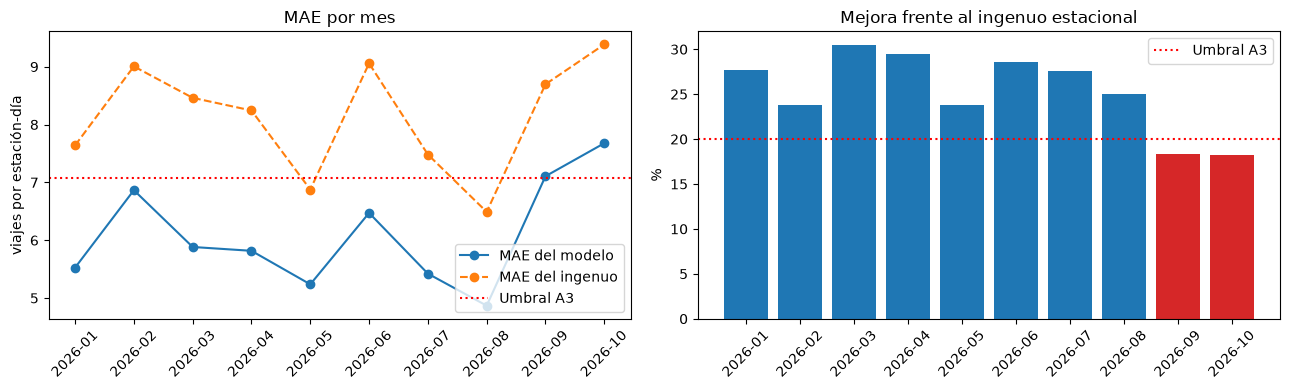

In [47]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(performance["mes"], performance["mae"], marker="o", label="MAE del modelo")
ax1.plot(performance["mes"], performance["mae_ingenuo"], marker="o", linestyle="--", label="MAE del ingenuo")
ax1.axhline((1 + MAE_ALERT_INCREASE) * baseline_metrics["mae"], color="red", linestyle=":", label="Umbral A3")
ax1.set_title("MAE por mes")
ax1.set_ylabel("viajes por estación-día")
ax1.tick_params(axis="x", rotation=45)
ax1.legend()
ax2.bar(performance["mes"], performance["mejora_vs_ingenuo"] * 100,
        color=["tab:red" if v < SKILL_ALERT_MIN else "tab:blue" for v in performance["mejora_vs_ingenuo"]])
ax2.axhline(SKILL_ALERT_MIN * 100, color="red", linestyle=":", label="Umbral A3")
ax2.set_title("Mejora frente al ingenuo estacional")
ax2.set_ylabel("%")
ax2.tick_params(axis="x", rotation=45)
ax2.legend()
fig.tight_layout()
fig.savefig(DRIFT_DIR / "monthly_performance.png", dpi=150)
plt.show()

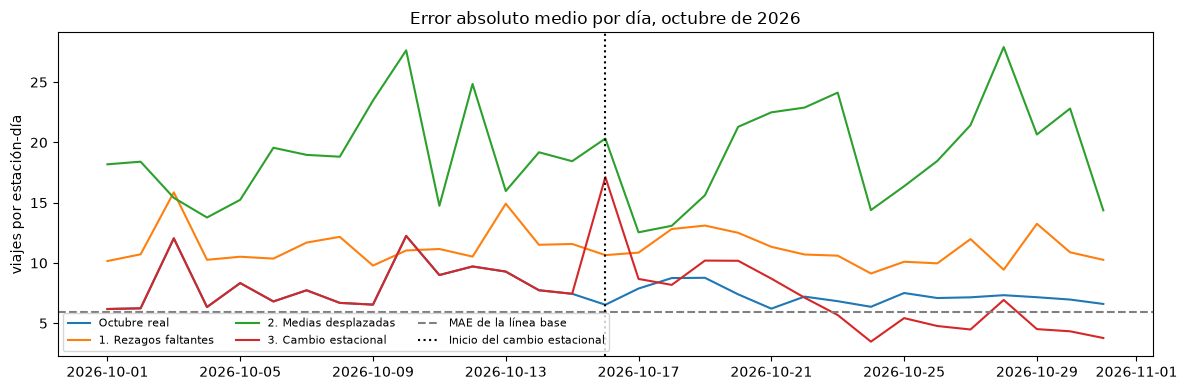

In [48]:
fig, ax = plt.subplots(figsize=(12, 4))
for name in daily_mae.columns:
    ax.plot(daily_mae.index, daily_mae[name], label=name)
ax.axhline(baseline_metrics["mae"], color="gray", linestyle="--", label="MAE de la línea base")
ax.axvline(DROP_START, color="black", linestyle=":", label="Inicio del cambio estacional")
ax.set_title("Error absoluto medio por día, octubre de 2026")
ax.set_ylabel("viajes por estación-día")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(DRIFT_DIR / "daily_error_scenarios.png", dpi=150)
plt.show()

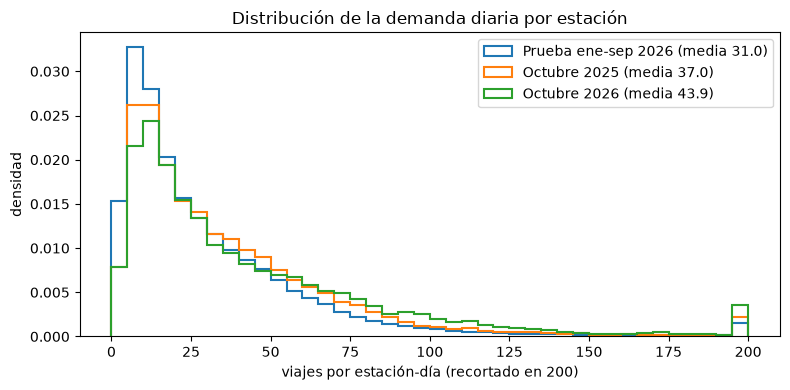

In [49]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0, 201, 5)
for name, data in [("Prueba ene-sep 2026", reference_test), ("Octubre 2025", october_2025),
                   ("Octubre 2026", current)]:
    ax.hist(data[TARGET_COLUMN].clip(upper=200), bins=bins, density=True, histtype="step",
            linewidth=1.5, label=f"{name} (media {data[TARGET_COLUMN].mean():.1f})")
ax.set_title("Distribución de la demanda diaria por estación")
ax.set_xlabel("viajes por estación-día (recortado en 200)")
ax.set_ylabel("densidad")
ax.legend()
fig.tight_layout()
fig.savefig(DRIFT_DIR / "demand_distribution.png", dpi=150)
plt.show()

### 5.14 Registro en MLflow
Registramos el monitoreo en un experimento aparte, `MiBici_Monitoreo_Drift`, para no mezclarlo con los entrenamientos. Una ejecución principal guarda las tablas, los reportes de Evidently y las gráficas; dentro de ella, una ejecución por escenario guarda sus métricas y qué alertas se activaron. Todas llevan la versión del modelo evaluado, así se puede rastrear qué modelo se monitoreó y con qué datos.

In [50]:
mlflow.set_experiment("MiBici_Monitoreo_Drift")
thresholds = {
    "missing_warning": MISSING_LEVELS[0], "missing_critical": MISSING_LEVELS[1],
    "bias_warning": BIAS_LEVELS[0], "bias_critical": BIAS_LEVELS[1],
    "mae_alert_increase": MAE_ALERT_INCREASE, "skill_alert_min": SKILL_ALERT_MIN,
    "psi_warning": PSI_LEVELS[0], "psi_critical": PSI_LEVELS[1],
    "operation_warning": OPERATION_LEVELS[0], "operation_critical": OPERATION_LEVELS[1],
    "dataset_drift_share": DATASET_DRIFT_SHARE, "ks_threshold": KS_THRESHOLD,
    "wasserstein_threshold": WASSERSTEIN_THRESHOLD,
}

with mlflow.start_run(run_name="monitoreo_octubre_2026") as parent:
    mlflow.set_tags({"model_uri": PHASE2_URI, "monitor_period": "2026-10",
                     "reference_period": "2026-01 a 2026-09", "seasonal_reference": "2025-10"})
    mlflow.log_params({**thresholds, "monitor_csv": MONITOR_CSV.name,
                       "monitor_rows": len(current), "new_stations": len(new_ids)})
    mlflow.log_metrics({"baseline_mae": baseline_metrics["mae"], "baseline_rmse": baseline_metrics["rmse"],
                        "baseline_skill_vs_naive": baseline_skill})
    for path in sorted(DRIFT_DIR.iterdir()):
        mlflow.log_artifact(str(path), "drift")

    for name, row in monitor_table.iloc[1:].iterrows():
        with mlflow.start_run(run_name=name, nested=True):
            mlflow.set_tag("model_uri", PHASE2_URI)
            mlflow.log_param("scenario", name)
            mlflow.log_metrics({
                "mae": row["mae"], "rmse": row["rmse"], "skill_vs_naive": row["mejora_vs_ingenuo"],
                "bias": row["sesgo"], "lag_1_missing": row["lag_1_vacío"],
                "drift_share": row["proporción_drift"], "mae_vs_baseline": row["mae_vs_base"],
                "psi_max": row["psi_máximo"], "active_stations_change": row["cambio_estaciones_activas"],
                "daily_trips_change": row["cambio_viajes_por_día"],
                **{flag: float(value) for flag, value in alerts.loc[name].items()},  # 0, 1 o 2
            })
            mlflow.set_tag("action", decisions.loc[name, "acción"])

print("Ejecución de monitoreo:", parent.info.run_id)
print(f"Artefactos registrados: {len(list(DRIFT_DIR.iterdir()))}")

Ejecución de monitoreo: be0e8ae4c5e444e79970bf59b9a7377a
Artefactos registrados: 9


### 5.15 Champion contra challenger
La acción para octubre real fue reentrenar. Aquí lo hacemos como se haría en producción: entrenamos un modelo nuevo (challenger), lo comparamos contra la v7, que es el modelo que estuvo en uso durante octubre, y solo si gana se le pasa el alias `champion`.

La v7 se entrenó con datos hasta diciembre de 2025, así que no conoce 2026: ni el nivel de demanda de este año ni la historia de las 99 estaciones nuevas. Los challengers usan los mismos hiperparámetros que la v7.

Además probamos una de las mejoras que dejamos en las conclusiones de la fase 2: días festivos. Seguimos el mismo proceso que propusimos ahí, una variable a la vez:

- Challenger A: mismo pipeline, solo reentrenado.
- Challenger B: igual que A más la variable `is_holiday`.

Para que la evaluación final no esté sesgada por la elección, separamos dos meses:

1. Selección en septiembre. A y B se entrenan con datos hasta agosto de 2026 y se comparan en septiembre. Se queda el de menor MAE.
2. Prueba en octubre. El elegido se vuelve a entrenar con datos hasta septiembre y se compara contra la v7 en octubre. Octubre no se usó para elegir, así que su resultado es una evaluación independiente, y la regla de promoción se aplica solo con él.

#### Variable de días festivos
Usamos la misma lista de días oficiales de descanso que armamos en el EDA de la fase 2 (notebook 05, y la función `plot_holiday_demand` del notebook 06 y de `plots.py`), que sigue la Ley Federal del Trabajo (art. 74): 1 de enero, primer lunes de febrero, tercer lunes de marzo, 1 de mayo, 16 de septiembre, tercer lunes de noviembre y 25 de diciembre. En ese análisis vimos que la demanda sí cambia en estos días (Navidad y Año Nuevo fueron los de menor uso).

La variable se calcula dentro del pipeline con `month`, `day_of_month` y `day_of_week`, que ya llegan al modelo. Así la API y su esquema no cambian: quien llama a `/predict` manda las mismas 18 variables. La única fecha de la lista que no podemos marcar es el 1 de octubre de 2024 (cambio de gobierno), porque depende del año y el modelo no recibe el año.

Abajo comprobamos que la variable marca exactamente los mismos días que la lista de la fase 2.


In [51]:
import time
from datetime import date, timedelta

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

from mibici_mlops.modeling.train import build_model_pipeline

HOLIDAY_DATES = [101, 501, 916, 1225]   # mes * 100 + día
HOLIDAY_MONDAYS = [21, 33, 113]         # mes * 10 + número de lunes: 1.º de febrero, 3.º de marzo y de noviembre


def add_holidays(features: pd.DataFrame) -> pd.DataFrame:
    features = features.copy()
    date_key = features["month"] * 100 + features["day_of_month"]
    monday_key = features["month"] * 10 + (features["day_of_month"] - 1) // 7 + 1
    holiday = date_key.isin(HOLIDAY_DATES) | ((features["day_of_week"] == 0) & monday_key.isin(HOLIDAY_MONDAYS))
    features["is_holiday"] = holiday.astype(int)
    return features


# Lista de la fase 2 (notebook 05), para comparar.
def nth_monday(year, month, occurrence):
    first_day = date(year, month, 1)
    return first_day + timedelta(days=(7 - first_day.weekday()) % 7 + 7 * (occurrence - 1))


phase2_holidays = {
    pd.Timestamp(day) for year in range(2020, 2027) for day in [
        date(year, 1, 1), nth_monday(year, 2, 1), nth_monday(year, 3, 3), date(year, 5, 1),
        date(year, 9, 16), nth_monday(year, 11, 3), date(year, 12, 25)]
}
calendar = add_holidays(dataset[["Fecha", "month", "day_of_month", "day_of_week"]].drop_duplicates("Fecha"))
marked = set(calendar.loc[calendar["is_holiday"] == 1, "Fecha"])
expected = {d for d in phase2_holidays if calendar["Fecha"].min() <= d <= calendar["Fecha"].max()}
assert marked == expected, "La variable no coincide con la lista de la fase 2"
print(f"is_holiday marca los mismos {len(marked)} días que la lista de la fase 2")
print(calendar.groupby(calendar["Fecha"].dt.year)["is_holiday"].sum().to_string())


is_holiday marca los mismos 47 días que la lista de la fase 2
Fecha
2020    7
2021    7
2022    7
2023    7
2024    7
2025    7
2026    5


#### Selección en septiembre
Entrenamos A y B con datos hasta el 31 de agosto de 2026. Cada entrenamiento puede tardar unos minutos.

In [52]:
SELECTION_START = pd.Timestamp("2026-09-01")
TRAIN_END = pd.Timestamp("2026-10-01")
phase2_rf = phase2_model.named_steps["model"]   # mismos hiperparámetros de la v7
CANDIDATES = {"Challenger A (reentrenado)": False, "Challenger B (+ festivos)": True}


def make_challenger(with_holidays: bool) -> Pipeline:
    if not with_holidays:
        return build_model_pipeline(clone(phase2_rf), FEATURE_COLUMNS)
    base = build_model_pipeline(clone(phase2_rf), FEATURE_COLUMNS + ["is_holiday"])
    return Pipeline([("holidays", FunctionTransformer(add_holidays)), *base.steps])


def fit_challenger(name: str, data: pd.DataFrame) -> Pipeline:
    start = time.perf_counter()
    model = make_challenger(CANDIDATES[name]).fit(data[FEATURE_COLUMNS], data[TARGET_COLUMN])
    print(f"{name}: {len(data):,} filas hasta {data['Fecha'].max().date()} | {time.perf_counter() - start:.0f} s")
    return model


train_selection = dataset.loc[dataset["Fecha"] < SELECTION_START]
selection_month = dataset.loc[(dataset["Fecha"] >= SELECTION_START) & (dataset["Fecha"] < TRAIN_END)]
selection_models = {name: fit_challenger(name, train_selection) for name in CANDIDATES}

/home/josel/mlops/equipo-8-mibici-mlops/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning:

`TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.



Challenger A (reentrenado): 785,290 filas hasta 2026-08-31 | 115 s


/home/josel/mlops/equipo-8-mibici-mlops/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning:

`TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.



Challenger B (+ festivos): 785,290 filas hasta 2026-08-31 | 120 s


Comparamos A y B en septiembre contra el mismo ingenuo estacional. La v7 aparece solo como referencia; la elección es entre A y B.

In [53]:
selection_naive = predict_seasonal_naive(train_selection, selection_month, TARGET_COLUMN)


def month_metrics(name: str, data: pd.DataFrame, predictions, naive) -> dict:
    predictions = np.clip(predictions, 0, None)
    model = regression_metrics(data[TARGET_COLUMN], predictions)
    return {"modelo": name, "mae": model["mae"], "rmse": model["rmse"],
            "mejora_vs_ingenuo": 1 - model["mae"] / regression_metrics(data[TARGET_COLUMN], naive)["mae"],
            "sesgo": float((predictions - data[TARGET_COLUMN]).mean())}


selection_table = pd.DataFrame(
    [month_metrics(f"v{phase2.version} (referencia)", selection_month,
                   phase2_model.predict(selection_month[FEATURE_COLUMNS]), selection_naive)]
    + [month_metrics(name, selection_month, model.predict(selection_month[FEATURE_COLUMNS]), selection_naive)
       for name, model in selection_models.items()]
).set_index("modelo")
best_name = selection_table.loc[list(CANDIDATES), "mae"].idxmin()
holidays_help = best_name == "Challenger B (+ festivos)"
selection_table.to_csv(DRIFT_DIR / "challenger_selection_september.csv")
print("Elegido en septiembre:", best_name, "| festivos", "mejoran" if holidays_help else "no mejoran", "a A")
selection_table.round(3)

Elegido en septiembre: Challenger B (+ festivos) | festivos mejoran a A


,mae,rmse,mejora_vs_ingenuo,sesgo
modelo,,,,
v7 (referencia),7.106,13.046,0.174,-2.550
Challenger A (reentrenado),7.048,12.838,0.181,-2.823
Challenger B (+ festivos),6.699,12.193,0.221,-2.965


#### Prueba en octubre
El elegido se vuelve a entrenar con datos hasta el 30 de septiembre, igual que se haría para desplegarlo, y se compara contra la v7 en octubre. También separamos estaciones con historia y nuevas, y vemos el 12 de octubre (Romería de Zapopan) como referencia de un día especial que no está en la lista de festivos.

In [54]:
train_recent = dataset.loc[dataset["Fecha"] < TRAIN_END]
final_challenger = fit_challenger(best_name, train_recent)


def evaluate_model(name: str, predictions: np.ndarray) -> dict:
    predictions = np.clip(predictions, 0, None)
    y = october[TARGET_COLUMN]
    known, new = ~october["new_station"], october["new_station"]
    oct_12 = october["Fecha"] == "2026-10-12"
    model = regression_metrics(y, predictions)
    return {
        "modelo": name, "mae": model["mae"], "rmse": model["rmse"],
        "mejora_vs_ingenuo": 1 - model["mae"] / regression_metrics(y, october["naive"])["mae"],
        "mae_con_historia": regression_metrics(y[known], predictions[known])["mae"],
        "mae_nuevas": regression_metrics(y[new], predictions[new])["mae"],
        "mae_12_oct": regression_metrics(y[oct_12], predictions[oct_12])["mae"],
        "sesgo": float((predictions - y).mean()),
    }


comparison_models = pd.DataFrame([
    evaluate_model(f"v{phase2.version} (en uso en octubre)", october["predicted"].to_numpy()),
    evaluate_model(f"{best_name}, entrenado hasta septiembre", final_challenger.predict(october[FEATURE_COLUMNS])),
]).set_index("modelo")
comparison_models.to_csv(DRIFT_DIR / "challenger_test_october.csv")
comparison_models.round(3)

/home/josel/mlops/equipo-8-mibici-mlops/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning:

`TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.



Challenger B (+ festivos): 799,264 filas hasta 2026-09-30 | 115 s


,mae,rmse,mejora_vs_ingenuo,mae_con_historia,mae_nuevas,mae_12_oct,sesgo
modelo,,,,,,,
v7 (en uso en octubre),7.677,15.145,0.182,8.658,3.966,9.711,-1.950
"Challenger B (+ festivos), entrenado hasta septiembre",7.422,13.961,0.209,8.352,3.901,10.455,-1.572


#### Decisión
La regla se fija antes de ver el resultado: el challenger gana si en octubre baja el MAE al menos 2 % frente a la v7 y no empeora el RMSE. Pedimos un margen para no cambiar de modelo por diferencias que pueden ser ruido.

En el notebook la promoción es una simulación mientras `AUTO_PROMOTE = False`: se muestra qué haría el pipeline y la decisión queda registrada en MLflow, pero no se cambia el alias ni la imagen. En el script del pipeline (al migrar) la promoción sí es automática bajo esta misma regla.

También revisamos qué versión tiene hoy el alias `champion`. Si ya es un modelo que salió de esta comparación y coincide con el elegido, no hay nada que hacer. Si no coincide, se avisa para decidirlo con el equipo, en lugar de cambiar el modelo en silencio.

In [55]:
MIN_IMPROVEMENT = 0.02

v7_row = comparison_models.iloc[0]
challenger_row = comparison_models.iloc[1]
improvement = 1 - challenger_row["mae"] / v7_row["mae"]
challenger_wins = bool(improvement >= MIN_IMPROVEMENT and challenger_row["rmse"] <= v7_row["rmse"])

registry = mlflow.MlflowClient()   # en la sección 3 el nombre client se usó para el TestClient
alias_version = registry.get_model_version_by_alias(REGISTERED_MODEL_NAME, MODEL_ALIAS)
from_this_comparison = alias_version.tags.get("source") == "challenger_octubre_2026"
same_candidate = alias_version.tags.get("candidate") == best_name

if challenger_wins and from_this_comparison and same_candidate:
    decision = "ya promovido"
    reason = f"el champion v{alias_version.version} es {best_name} entrenado hasta septiembre"
elif challenger_wins and from_this_comparison:
    decision = "revisar con el equipo"
    reason = (f"gana {best_name}, pero el champion v{alias_version.version} es "
              f"{alias_version.tags.get('candidate')}")
elif challenger_wins:
    decision = "promover"
    reason = f"MAE {improvement:.1%} menor que v{phase2.version} y RMSE {v7_row['rmse']:.2f} a {challenger_row['rmse']:.2f}"
elif from_this_comparison:
    decision = "revisar con el equipo"
    reason = f"el challenger ya no gana a la v{phase2.version}, pero el champion es v{alias_version.version}"
else:
    decision = "mantener champion"
    reason = (f"mejora de MAE {improvement:.1%} (mínimo {MIN_IMPROVEMENT:.0%}) o RMSE peor "
              f"({v7_row['rmse']:.2f} a {challenger_row['rmse']:.2f})")

print(f"Mejora de MAE contra v{phase2.version}: {improvement:.1%} | "
      f"RMSE {v7_row['rmse']:.3f} contra {challenger_row['rmse']:.3f}")
print(f"Champion actual: v{alias_version.version} | decisión: {decision} | {reason}")

Mejora de MAE contra v7: 3.3% | RMSE 15.145 contra 13.961
Champion actual: v10 | decisión: ya promovido | el champion v10 es Challenger B (+ festivos) entrenado hasta septiembre


#### Registro en MLflow
La comparación siempre queda registrada como una ejecución con la decisión y su motivo. El modelo solo se registra como versión nueva y recibe el alias `champion` si la decisión es promover y `AUTO_PROMOTE` es `True`.

In [56]:
promote_now = decision == "promover" and AUTO_PROMOTE

mlflow.set_experiment("MiBici_Champion_Challenger")
with mlflow.start_run(run_name="challenger_octubre_2026") as challenger_run:
    mlflow.set_tags({"reference_uri": PHASE2_URI, "deployed_champion": alias_version.version,
                     "candidate": best_name, "decision": decision, "reason": reason,
                     "auto_promote": str(AUTO_PROMOTE), "selection_period": "2026-09",
                     "test_period": "2026-10", "train_end": str(train_recent["Fecha"].max().date())})
    mlflow.log_params({"min_improvement": MIN_IMPROVEMENT, "train_rows": len(train_recent),
                       "holidays": CANDIDATES[best_name],
                       **{f"rf_{k}": v for k, v in phase2_rf.get_params().items()
                          if k in ("n_estimators", "max_depth", "max_features", "max_samples", "min_samples_leaf")}})
    for name, row in selection_table.iterrows():
        prefix = "v7" if name.startswith("v") else ("challenger_b" if "B" in name else "challenger_a")
        mlflow.log_metrics({f"sep_{prefix}_{k}": float(v) for k, v in row.items()})
    for prefix, (_, row) in zip(["v7", "challenger"], comparison_models.iterrows()):
        mlflow.log_metrics({f"oct_{prefix}_{k}": float(v) for k, v in row.items()})
    mlflow.log_metrics({"mae_improvement": improvement, "challenger_wins": float(challenger_wins)})
    mlflow.log_artifact(str(DRIFT_DIR / "challenger_selection_september.csv"))
    mlflow.log_artifact(str(DRIFT_DIR / "challenger_test_october.csv"))
    if promote_now:
        model_info = mlflow.sklearn.log_model(
            final_challenger, name="model", registered_model_name=REGISTERED_MODEL_NAME,
            serialization_format="cloudpickle", input_example=october[FEATURE_COLUMNS].head(5),
        )

print("Ejecución:", challenger_run.info.run_id, "| decisión:", decision)

Ejecución: 279540ea54a5433d9865f90e66d2c557 | decisión: ya promovido


Si se promovió, la versión nueva recibe las etiquetas de la decisión y el alias `champion`. La versión anterior no se borra, así que el cambio se puede regresar con una línea.

In [57]:
if promote_now:
    new_version = model_info.registered_model_version
    version_tags = {"source": "challenger_octubre_2026", "decision": decision, "reason": reason,
                    "replaces_version": alias_version.version, "candidate": best_name,
                    "train_end": str(train_recent["Fecha"].max().date())}
    for key, value in version_tags.items():
        registry.set_model_version_tag(REGISTERED_MODEL_NAME, new_version, key, str(value))
    registry.set_registered_model_alias(REGISTERED_MODEL_NAME, "challenger", new_version)
    registry.set_registered_model_alias(REGISTERED_MODEL_NAME, MODEL_ALIAS, new_version)
    print(f"Alias {MODEL_ALIAS}: versión {alias_version.version} cambia a {new_version}")
    print(f"Para regresar: registry.set_registered_model_alias('{REGISTERED_MODEL_NAME}', "
          f"'{MODEL_ALIAS}', {alias_version.version})")
elif decision == "promover":
    print(f"Simulación: el pipeline promovería a {best_name}. Para hacerlo aquí, AUTO_PROMOTE = True.")
else:
    print(f"El alias {MODEL_ALIAS} sigue en la versión {alias_version.version} ({decision}).")

El alias champion sigue en la versión 10 (ya promovido).


### 5.16 Despliegue del nuevo champion
Si el alias `champion` cambió (porque 5.15 promovió con `AUTO_PROMOTE = True`, o porque el alias se movió fuera del notebook), el servicio tiene que usar la versión nueva. Esta celda lo hace todo sin pasos manuales:

1. Vuelve a exportar con la función de 2.6, que toma el alias, y revisa las predicciones de la muestra de referencia.
2. Reconstruye la imagen con la siguiente etiqueta (1.1.0), la levanta y compara la muestra de referencia predicha por el contenedor contra la del modelo, igual que en 4.7.
3. Si la comparación sale bien, publica la etiqueta nueva y `latest` en DockerHub con la función de 4.9.

Si Docker no está abierto, el modelo nuevo queda exportado en `models/serving` y la imagen se construye y publica en la siguiente corrida completa del notebook, porque la sección 4 ya tomará la versión nueva.

In [58]:
serving_version = registry.get_model_version_by_alias(REGISTERED_MODEL_NAME, MODEL_ALIAS)
exported_version = json.loads((SERVING_DIR / "metadata.json").read_text())["model_version"]

if exported_version == str(serving_version.version):
    print(f"models/serving ya tiene el champion (versión {exported_version}); la imagen está al día.")
else:
    reference = export_serving_model(serving_version)
    served = mlflow.sklearn.load_model(str(SERVING_DIR / "model"))
    assert np.allclose(served.predict(reference[FEATURE_COLUMNS]), reference["reference_prediction"])
    SERVED_VERSION = str(serving_version.version)
    IMAGE_TAG = RELEASES.get(SERVED_VERSION, f"1.{len(RELEASES)}.0")
    print(f"models/serving cambió de la versión {exported_version} a la {SERVED_VERSION}; etiqueta {IMAGE_TAG}")

    docker_status = run(["docker", "version", "--format", "{{.Server.Version}}"], check=False)
    if "failed to connect" in docker_status or "Cannot connect" in docker_status:
        print("Docker no está abierto. La imagen se construirá en la siguiente corrida completa.")
    else:
        # Contexto de construcción con el modelo nuevo
        shutil.rmtree(DOCKER_DIR / "models" / "serving")
        shutil.copytree(SERVING_DIR, DOCKER_DIR / "models" / "serving")
        start = time.perf_counter()
        run(["docker", "build", "-t", IMAGE, str(DOCKER_DIR)])
        print(f"Imagen construida en {time.perf_counter() - start:.0f} s")

        # Levantar el contenedor y esperar a que cargue el modelo
        run(["docker", "rm", "-f", CONTAINER], check=False)
        run(["docker", "run", "-d", "--name", CONTAINER, "-p", f"{PORT}:8000", IMAGE])
        health_body = {}
        for attempt in range(60):
            try:
                health_body = requests.get(f"{BASE_URL}/health", timeout=2).json()
                if health_body.get("model_loaded"):
                    break
            except requests.RequestException:
                pass
            time.sleep(1)
        assert health_body.get("model_version") == SERVED_VERSION, health_body

        # Misma muestra de referencia, ahora predicha por el contenedor
        payload = {"instances": [to_instance(r) for r in reference.to_dict(orient="records")]}
        response = requests.post(f"{BASE_URL}/predict", json=payload, timeout=60)
        docker_predictions = np.array([p["predicted_trips"] for p in response.json()["predictions"]])
        expected = reference["reference_prediction"].clip(lower=0).to_numpy()
        difference = float(np.abs(docker_predictions - expected).max())
        run(["docker", "rm", "-f", CONTAINER], check=False)

        summary = {"model_version": SERVED_VERSION, "image_tag": IMAGE_TAG, "rows": len(reference),
                   "max_abs_difference": difference, "reproducible": difference < 1e-4}
        repro_dir = ROOT / "reports" / "reproducibility"
        (repro_dir / f"docker_summary_v{SERVED_VERSION}.json").write_text(json.dumps(summary, indent=2))
        print(summary)

        if summary["reproducible"]:
            publish(IMAGE_TAG)
        else:
            print("La imagen no reproduce la muestra de referencia; no se publica.")

models/serving ya tiene el champion (versión 10); la imagen está al día.


## 6. Pruebas unitarias y de integración
En las secciones anteriores ya revisamos cada parte a mano: que el `.joblib` da lo mismo que la v7 del registro, que la API valida bien las entradas, que la imagen de Docker responde igual y que las alertas de drift dan la acción esperada. Ahora lo pasamos a pruebas automáticas con `pytest`, para que cualquiera del equipo las pueda correr con un solo comando.

Las 17 pruebas que ya teníamos en `tests/` se quedan igual. Las nuevas cubren lo que se agregó en esta entrega:

| Archivo | Tipo | Qué revisa |
|---|---|---|
| `test_metrics.py` | unitaria | MAE, RMSE, línea base ingenua y mejora contra ella |
| `test_api.py` | unitaria | esquema de entrada, respuesta de `/predict`, errores 422 y 503, documentación |
| `test_reproducibility.py` | unitaria | misma semilla, mismo resultado; el modelo de `models/serving` reproduce su muestra de referencia |
| `test_drift.py` | unitaria | PSI, tabla de drift, niveles de las alertas A1 a A5, persistencia y acción propuesta |
| `test_calendar.py` | unitaria | variable de días festivos del challenger |
| `test_integration_pipeline.py` | integración | del CSV crudo a las métricas: limpieza, demanda diaria, variables, entrenamiento y predicción directa y por la API |

Por ahora los archivos se escriben en `build/tests_entrega/` con `%%writefile`. En la migración pasan a `tests/` y todo se corre con `pytest -q`. Las pruebas usan datos pequeños generados en el momento, así que no necesitan los CSV originales. Solo las pruebas del modelo desplegado leen `models/serving/`, y si no existe se saltan.

### 6.1 Carpeta de pruebas

In [59]:
import importlib

TESTS_DIR = ROOT / "build" / "tests_entrega"
if TESTS_DIR.exists():
    shutil.rmtree(TESTS_DIR)
TESTS_DIR.mkdir(parents=True)
assert (DOCKER_DIR / "app.py").is_file(), "Primero ejecutar 4.1: las pruebas usan ese app.py"
print("Pruebas en:", TESTS_DIR)

Pruebas en: /home/josel/mlops/equipo-8-mibici-mlops/build/tests_entrega


### 6.2 Funciones de monitoreo y de calendario en módulos
Para probar con `pytest` las funciones de la sección 5 necesitan estar en un archivo. Las juntamos en `monitoring.py`, sin depender de variables del notebook: los valores de referencia (MAE base, demanda media, etc.) entran como argumentos. La variable de festivos de 5.15 va en `calendar_features.py`. En la migración serán `mibici_mlops/monitoring.py` y parte de `mibici_mlops/features.py`.

In [60]:
%%writefile ../build/tests_entrega/monitoring.py
"""Monitoreo de data drift y alertas del modelo de salidas diarias (sección 5 del notebook 07)."""

import numpy as np
import pandas as pd
from scipy.stats import ks_2samp, wasserstein_distance

KS_THRESHOLD = 0.1
WASSERSTEIN_THRESHOLD = 0.1
DATASET_DRIFT_SHARE = 0.3

# Niveles: (advertencia, crítica)
MISSING_LEVELS = (0.05, 0.15)     # puntos de lag_1 vacío por arriba de la línea base
BIAS_LEVELS = (0.10, 0.20)        # sesgo como fracción de la demanda media de referencia
PSI_LEVELS = (0.10, 0.25)
OPERATION_LEVELS = (0.15, 0.30)   # cambio relativo de estaciones activas o viajes por día
MAE_ALERT_INCREASE = 0.20
SKILL_ALERT_MIN = 0.20
LEVEL_NAMES = {0: "-", 1: "advertencia", 2: "crítica"}


def psi(reference: pd.Series, current: pd.Series, bins: int = 10) -> float:
    """Índice de estabilidad con cortes por cuantiles de la referencia."""
    reference, current = reference.dropna(), current.dropna()
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        edges = np.unique(np.concatenate([edges, [reference.min() - 0.5, reference.max() + 0.5]]))
    edges[0], edges[-1] = -np.inf, np.inf
    ref_share = np.histogram(reference, edges)[0] / len(reference)
    cur_share = np.histogram(current, edges)[0] / len(current)
    ref_share, cur_share = np.clip(ref_share, 1e-4, None), np.clip(cur_share, 1e-4, None)
    return float(np.sum((cur_share - ref_share) * np.log(cur_share / ref_share)))


def drift_table(reference: pd.DataFrame, current: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """KS, Wasserstein normalizado y PSI por variable; drift si KS o Wasserstein pasan 0.1."""
    rows = []
    for column in columns:
        ref, cur = reference[column].dropna(), current[column].dropna()
        ks = ks_2samp(ref, cur)
        scale = ref.std() if ref.std() > 0 else 1.0
        rows.append({
            "variable": column,
            "media_ref": ref.mean(), "media_actual": cur.mean(),
            "ks": ks.statistic, "ks_pvalue": ks.pvalue,
            "wasserstein_norm": wasserstein_distance(ref, cur) / scale,
            "psi": psi(ref, cur),
        })
    table = pd.DataFrame(rows)
    table["drift"] = (table["ks"] > KS_THRESHOLD) | (table["wasserstein_norm"] > WASSERSTEIN_THRESHOLD)
    return table


def level(value: float, limits: tuple[float, float]) -> int:
    """0 sin alerta, 1 advertencia, 2 crítica."""
    warning, critical = limits
    return 2 if value > critical else 1 if value > warning else 0


def daily_operation(data: pd.DataFrame, target: str = "target") -> tuple[float, float]:
    """Estaciones activas por día y viajes totales por día."""
    by_day = data.groupby("Fecha")
    return by_day["Origen_Id"].nunique().mean(), by_day[target].sum().mean()


def performance_level(mae: float, skill: float, baseline_mae: float) -> int:
    """A3: advertencia con una de las dos condiciones, crítica con las dos."""
    return int(mae > (1 + MAE_ALERT_INCREASE) * baseline_mae) + int(skill < SKILL_ALERT_MIN)


def alert_levels(row: pd.Series, baseline_mae: float, baseline_missing: float,
                 reference_demand: float) -> dict:
    """Nivel de las cinco alertas para un periodo o escenario (una fila de monitor_table)."""
    drift = level(row["psi_máximo"], PSI_LEVELS)
    if row["proporción_drift"] > DATASET_DRIFT_SHARE:
        drift = max(drift, 1)
    operation = max(abs(row["cambio_estaciones_activas"]), abs(row["cambio_viajes_por_día"]))
    return {
        "A1_datos_faltantes": level(row["lag_1_vacío"] - baseline_missing, MISSING_LEVELS),
        "A2_sesgo": level(abs(row["sesgo"]) / reference_demand, BIAS_LEVELS),
        "A3_desempeño": performance_level(row["mae"], row["mejora_vs_ingenuo"], baseline_mae),
        "A4_drift": drift,
        "A5_operación": level(operation, OPERATION_LEVELS),
    }


def decide(levels, previous_a3: int = 0) -> str:
    """Acción propuesta. Los problemas de datos van primero porque reentrenar no los arregla."""
    data_problem = max(levels["A1_datos_faltantes"], levels["A2_sesgo"])
    if data_problem == 2:
        return "Revisar el pipeline de datos (no reentrenar)"
    if data_problem == 1:
        return "Revisar los datos de entrada"
    if levels["A3_desempeño"] == 2:
        if previous_a3 == 2:
            return "Reentrenar: A3 crítica dos meses seguidos"
        return "Vigilar y confirmar con el siguiente mes"
    if levels["A5_operación"] == 2:
        return "Revisar con operación el cambio de la red"
    if max(levels.values() if isinstance(levels, dict) else levels) >= 1:
        return "Vigilar"
    return "Sin acción"

Writing ../build/tests_entrega/monitoring.py


In [61]:
%%writefile ../build/tests_entrega/calendar_features.py
"""Variable de días festivos del challenger (sección 5.15 del notebook 07).

Lista de la fase 2 (notebook 05): descansos obligatorios de la Ley Federal del Trabajo.
"""

import pandas as pd

HOLIDAY_DATES = [101, 501, 916, 1225]   # mes * 100 + día
HOLIDAY_MONDAYS = [21, 33, 113]         # mes * 10 + número de lunes


def add_holidays(features: pd.DataFrame) -> pd.DataFrame:
    """Agregar is_holiday a partir de month, day_of_month y day_of_week."""
    features = features.copy()
    date_key = features["month"] * 100 + features["day_of_month"]
    monday_key = features["month"] * 10 + (features["day_of_month"] - 1) // 7 + 1
    holiday = date_key.isin(HOLIDAY_DATES) | ((features["day_of_week"] == 0) & monday_key.isin(HOLIDAY_MONDAYS))
    features["is_holiday"] = holiday.astype(int)
    return features

Writing ../build/tests_entrega/calendar_features.py


Antes de escribir las pruebas confirmamos que los módulos dan exactamente lo mismo que el notebook: la misma tabla de drift, los mismos niveles de alerta, el mismo nivel de A3 en septiembre, las mismas acciones y los mismos días festivos.

In [62]:
if str(TESTS_DIR) not in sys.path:
    sys.path.insert(0, str(TESTS_DIR))
import calendar_features
import monitoring
importlib.reload(monitoring)
importlib.reload(calendar_features)

pd.testing.assert_frame_equal(monitoring.drift_table(reference_test, current, MONITORED), drift_vs_test)

module_levels = pd.DataFrame({
    name: monitoring.alert_levels(row, baseline_metrics["mae"], baseline_missing, reference_demand)
    for name, row in monitor_table.iterrows()
}).T
assert (module_levels.astype(int) == alerts.astype(int)).all().all()
assert monitoring.performance_level(september["mae"], september["mejora_vs_ingenuo"],
                                    baseline_metrics["mae"]) == september_a3
module_actions = [monitoring.decide(module_levels.loc[name], previous_a3[name]) for name in module_levels.index]
assert module_actions == decisions["acción"].tolist()

days = dataset[["Fecha", "month", "day_of_month", "day_of_week"]].drop_duplicates("Fecha")
assert (calendar_features.add_holidays(days)["is_holiday"] == add_holidays(days)["is_holiday"]).all()
print("Los módulos coinciden con el notebook en drift, alertas, acciones y días festivos")

Los módulos coinciden con el notebook en drift, alertas, acciones y días festivos


### 6.3 Datos y modelo de prueba
`helpers.py` genera demanda diaria sintética con las 18 variables reales (4 estaciones, enero a abril de 2025, patrón entre semana y fin de semana). `conftest.py` arma con ella un modelo pequeño (10 árboles) y lo guarda en formato MLflow, igual que el modelo de `models/serving/`. Así las pruebas tardan segundos y no dependen del modelo de 184 MB.

In [63]:
%%writefile ../build/tests_entrega/helpers.py
"""Datos sintéticos y utilidades que comparten las pruebas."""

import numpy as np
import pandas as pd

from mibici_mlops.config import FEATURE_COLUMNS, POI_COLUMNS, SEED


def make_station_days(n_stations: int = 4, start="2025-01-01", end="2025-04-30", seed=SEED):
    """Demanda diaria con patrón semanal y un nivel distinto por estación."""
    rng = np.random.default_rng(seed)
    dates = pd.date_range(start, end)
    rows = []
    for station in range(1, n_stations + 1):
        weekly = np.where(dates.day_of_week < 5, 1.0, 0.5)
        rows.append(pd.DataFrame({
            "Origen_Id": station, "Fecha": dates, "target": rng.poisson(10 * station * weekly),
        }))
    data = pd.concat(rows, ignore_index=True)
    data["day_of_week"] = data["Fecha"].dt.day_of_week
    data["month"] = data["Fecha"].dt.month
    data["weather_zone"] = data["Origen_Id"] % 2
    for i, column in enumerate(POI_COLUMNS):
        data[column] = (data["Origen_Id"] * (i + 1)) % 5
    return data


def to_instance(row: dict) -> dict:
    """Una fila del dataset en el formato JSON que recibe /predict."""
    instance = {}
    for column in FEATURE_COLUMNS:
        value = row[column]
        if pd.isna(value):
            instance[column] = None
        elif column.startswith(("lag_", "roll_")):
            instance[column] = float(value)
        else:
            instance[column] = int(value)
    return instance

Writing ../build/tests_entrega/helpers.py


In [64]:
%%writefile ../build/tests_entrega/conftest.py
"""Fixtures de las pruebas de la entrega final."""

import json
from pathlib import Path
import sys

import pytest

ROOT = Path(__file__).resolve().parent
while not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent
for path in (ROOT, ROOT / "build" / "docker"):  # en la migración la API estará en mibici_mlops
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from helpers import make_station_days  # noqa: E402

from mibici_mlops.config import FEATURE_COLUMNS, LAGS, ROLLING_WINDOWS, TARGET_COLUMN  # noqa: E402
from mibici_mlops.features import build_model_dataset  # noqa: E402

SERVING_DIR = ROOT / "models" / "serving"


def pytest_configure(config):
    config.addinivalue_line("markers", "integration: prueba de extremo a extremo")


@pytest.fixture(scope="session")
def model_dataset():
    return build_model_dataset(make_station_days(), 1, LAGS, ROLLING_WINDOWS, TARGET_COLUMN)


@pytest.fixture(scope="session")
def trained_pipeline(model_dataset):
    from mibici_mlops.modeling.train import train_final_model

    return train_final_model("Random Forest", {"n_estimators": 10, "max_depth": 5},
                             model_dataset, FEATURE_COLUMNS, TARGET_COLUMN)


@pytest.fixture(scope="session")
def mlflow_model_dir(trained_pipeline, tmp_path_factory):
    """El modelo pequeño guardado como lo deja la sección 2.6: carpeta MLflow + metadata.json."""
    import mlflow.sklearn

    root = tmp_path_factory.mktemp("serving")
    mlflow.sklearn.save_model(trained_pipeline, str(root / "model"),
                              serialization_format="cloudpickle",
                              pip_requirements=["scikit-learn"])
    (root / "metadata.json").write_text(
        json.dumps({"model_name": "mibici_salidas_diarias", "model_version": "prueba"}))
    return root / "model"


def start_client(model_uri, monkeypatch):
    from fastapi.testclient import TestClient

    import app as service

    monkeypatch.setattr(service, "MODEL_URI", str(model_uri))
    return TestClient(service.app)


@pytest.fixture
def client(mlflow_model_dir, monkeypatch):
    with start_client(mlflow_model_dir, monkeypatch) as test_client:  # el with carga el modelo
        yield test_client


@pytest.fixture
def client_without_model(tmp_path, monkeypatch):
    with start_client(tmp_path / "no_existe", monkeypatch) as test_client:
        yield test_client

Writing ../build/tests_entrega/conftest.py


### 6.4 Métricas

In [65]:
%%writefile ../build/tests_entrega/test_metrics.py
"""Pruebas unitarias de las métricas y de la línea base ingenua."""

import numpy as np
import pandas as pd
import pytest

from mibici_mlops.modeling.evaluate import (
    NAIVE_BASELINE, add_skill, predict_seasonal_naive, predict_station_weekday, regression_metrics,
)


def test_metrics_with_known_values():
    metrics = regression_metrics([0, 2, 4], [1, 2, 7])
    assert metrics["mae"] == pytest.approx(4 / 3)
    assert metrics["rmse"] == pytest.approx(np.sqrt(10 / 3))


def test_perfect_prediction_has_zero_error():
    assert regression_metrics([3, 5, 8], [3, 5, 8]) == {"mae": 0.0, "rmse": 0.0}


def test_rmse_is_never_below_mae():
    rng = np.random.default_rng(0)
    metrics = regression_metrics(rng.poisson(10, 200), rng.poisson(10, 200))
    assert metrics["rmse"] >= metrics["mae"]


def test_naive_uses_lag_7_and_falls_back_to_station_weekday():
    train = pd.DataFrame({"Origen_Id": [1, 1, 2], "day_of_week": [0, 0, 0], "target": [10, 20, 40]})
    new = pd.DataFrame({"Origen_Id": [1, 1, 3], "day_of_week": [0, 0, 0], "lag_7": [7.0, None, None]})
    naive = predict_seasonal_naive(train, new)
    assert naive.tolist() == pytest.approx([7.0, 15.0, 70 / 3])  # 70/3: promedio global del lunes


def test_station_weekday_baseline_covers_new_stations():
    train = pd.DataFrame({"Origen_Id": [1, 2], "day_of_week": [3, 3], "target": [10, 30]})
    new = pd.DataFrame({"Origen_Id": [99], "day_of_week": [3]})
    assert predict_station_weekday(train, new).iloc[0] == pytest.approx(20)


def test_skill_is_improvement_over_naive():
    results = pd.DataFrame({"cutoff": ["2025-01", "2025-02"], "mae": [5.0, 9.0]})
    baseline = pd.DataFrame({"cutoff": ["2025-01", "2025-02"],
                             "model": [NAIVE_BASELINE] * 2, "mae": [10.0, 9.0]})
    assert add_skill(results, baseline)["skill_vs_naive"].tolist() == pytest.approx([0.5, 0.0])

Writing ../build/tests_entrega/test_metrics.py


### 6.5 Servicio FastAPI
Son las mismas revisiones de 3.4 a 3.8, ahora con el `app.py` de la imagen de Docker y el modelo pequeño.

In [66]:
%%writefile ../build/tests_entrega/test_api.py
"""Pruebas del servicio: contrato de entrada y salida, y manejo de errores."""

import math

from helpers import to_instance
import pytest

from mibici_mlops.config import FEATURE_COLUMNS
from app import EXAMPLE_INSTANCE, StationDayFeatures


def test_schema_has_the_model_features_in_order():
    assert list(StationDayFeatures.model_fields) == FEATURE_COLUMNS


def test_health_reports_loaded_model(client):
    body = client.get("/health").json()
    assert body == {"status": "ok", "model_loaded": True,
                    "model_name": "mibici_salidas_diarias", "model_version": "prueba"}


def test_example_instance_gets_a_prediction(client):
    response = client.post("/predict", json={"instances": [EXAMPLE_INSTANCE]})
    assert response.status_code == 200
    prediction = response.json()["predictions"][0]
    assert prediction["Origen_Id"] == EXAMPLE_INSTANCE["Origen_Id"]
    assert prediction["predicted_trips"] >= 0


def test_api_matches_the_pipeline(client, model_dataset, trained_pipeline):
    rows = model_dataset.iloc[-20:]
    response = client.post("/predict", json={"instances": [to_instance(r) for r in rows.to_dict("records")]})
    served = [p["predicted_trips"] for p in response.json()["predictions"]]
    expected = trained_pipeline.predict(rows[FEATURE_COLUMNS]).clip(min=0)
    assert served == pytest.approx(expected, abs=1e-4)


def test_new_station_without_history_is_accepted(client):
    instance = {**EXAMPLE_INSTANCE, "Origen_Id": 9999, "lag_1": None, "lag_7": None, "lag_14": None,
                "roll_mean_7": None, "roll_mean_28": None, "active_days_7": 0, "active_days_28": 0}
    response = client.post("/predict", json={"instances": [instance]})
    assert response.status_code == 200
    assert math.isfinite(response.json()["predictions"][0]["predicted_trips"])


@pytest.mark.parametrize("change", [
    {"day_of_week": 7}, {"month": 13}, {"active_days_7": 8}, {"lag_1": -3},
    {"Origen_Id": "estacion"}, {"variable_extra": 1},
])
def test_invalid_values_return_422(client, change):
    response = client.post("/predict", json={"instances": [{**EXAMPLE_INSTANCE, **change}]})
    assert response.status_code == 422


def test_missing_feature_returns_422(client):
    instance = {k: v for k, v in EXAMPLE_INSTANCE.items() if k != "month"}
    assert client.post("/predict", json={"instances": [instance]}).status_code == 422


def test_empty_request_returns_422(client):
    assert client.post("/predict", json={"instances": []}).status_code == 422


def test_without_model_returns_503(client_without_model):
    assert client_without_model.get("/health").json()["model_loaded"] is False
    response = client_without_model.post("/predict", json={"instances": [EXAMPLE_INSTANCE]})
    assert response.status_code == 503


def test_openapi_documents_predict(client):
    schema = client.get("/openapi.json").json()
    assert "post" in schema["paths"]["/predict"]
    assert "StationDayFeatures" in schema["components"]["schemas"]

Writing ../build/tests_entrega/test_api.py


### 6.6 Reproducibilidad
La primera prueba entrena dos veces con la misma semilla. Como el Random Forest usa `n_jobs=-1`, el orden en que se suman los árboles puede cambiar y dejar diferencias de 1e-14, por eso comparamos con tolerancia (lo mismo vimos en 2.5). La segunda revisa que el formato MLflow no cambia las predicciones. Las dos últimas usan el modelo desplegado en `models/serving` (el champion vigente) y su muestra de referencia de 2.6.

In [67]:
%%writefile ../build/tests_entrega/test_reproducibility.py
"""Reproducibilidad: misma semilla y mismo modelo guardado dan los mismos resultados."""

import json

import mlflow.sklearn
import numpy as np
import pandas as pd
import pytest

from conftest import SERVING_DIR
from mibici_mlops.config import FEATURE_COLUMNS, REGISTERED_MODEL_NAME, TARGET_COLUMN
from mibici_mlops.modeling.evaluate import regression_metrics
from mibici_mlops.modeling.train import train_final_model

needs_serving = pytest.mark.skipif(
    not (SERVING_DIR / "reference_sample.csv").is_file(),
    reason="Falta models/serving (se crea en la sección 2.6)",
)


def test_same_seed_gives_same_predictions(model_dataset):
    params = {"n_estimators": 10, "max_depth": 5}
    first = train_final_model("Random Forest", params, model_dataset, FEATURE_COLUMNS)
    second = train_final_model("Random Forest", params, model_dataset, FEATURE_COLUMNS)
    np.testing.assert_allclose(first.predict(model_dataset[FEATURE_COLUMNS]),
                               second.predict(model_dataset[FEATURE_COLUMNS]), rtol=0, atol=1e-9)


def test_mlflow_format_keeps_predictions(mlflow_model_dir, trained_pipeline, model_dataset):
    loaded = mlflow.sklearn.load_model(str(mlflow_model_dir))
    np.testing.assert_allclose(loaded.predict(model_dataset[FEATURE_COLUMNS]),
                               trained_pipeline.predict(model_dataset[FEATURE_COLUMNS]),
                               rtol=0, atol=1e-9)


@needs_serving
def test_serving_metadata_describes_the_model():
    meta = json.loads((SERVING_DIR / "metadata.json").read_text())
    assert meta["model_name"] == REGISTERED_MODEL_NAME
    assert meta["registry_uri"] == f"models:/{REGISTERED_MODEL_NAME}/{meta['model_version']}"
    assert meta["features"] == FEATURE_COLUMNS
    assert meta["seed"] == 42


@needs_serving
def test_serving_model_reproduces_reference_sample():
    reference = pd.read_csv(SERVING_DIR / "reference_sample.csv")
    model = mlflow.sklearn.load_model(str(SERVING_DIR / "model"))
    predictions = model.predict(reference[FEATURE_COLUMNS])
    np.testing.assert_allclose(predictions, reference["reference_prediction"], rtol=0, atol=1e-6)
    current = regression_metrics(reference[TARGET_COLUMN], predictions)
    expected = regression_metrics(reference[TARGET_COLUMN], reference["reference_prediction"])
    assert current == pytest.approx(expected, abs=1e-9)

Writing ../build/tests_entrega/test_reproducibility.py


### 6.7 Drift, alertas y festivos
Probamos cada alerta por separado con un caso que debe activarla y uno que no, los dos niveles, la regla de los dos meses para reentrenar y el orden de prioridad de las acciones. También la variable de festivos con fechas conocidas de 2025.

In [68]:
%%writefile ../build/tests_entrega/test_drift.py
"""Pruebas unitarias del monitoreo de drift (monitoring.py)."""

import numpy as np
import pandas as pd
import pytest

import monitoring

BASE = {"baseline_mae": 6.0, "baseline_missing": 0.10, "reference_demand": 30.0}


def period(**changes) -> pd.Series:
    """Un periodo sin problemas; cada prueba cambia solo lo que quiere revisar."""
    row = {"mae": 6.0, "mejora_vs_ingenuo": 0.25, "sesgo": 0.0, "lag_1_vacío": 0.10,
           "proporción_drift": 0.0, "psi_máximo": 0.02,
           "cambio_estaciones_activas": 0.0, "cambio_viajes_por_día": 0.0}
    return pd.Series({**row, **changes})


@pytest.fixture
def samples():
    rng = np.random.default_rng(42)
    reference = pd.DataFrame({"estable": rng.normal(10, 2, 5_000), "desplazada": rng.normal(10, 2, 5_000)})
    current = pd.DataFrame({"estable": rng.normal(10, 2, 5_000), "desplazada": rng.normal(13, 2, 5_000)})
    return reference, current


def test_psi_is_near_zero_for_the_same_distribution(samples):
    reference, current = samples
    assert monitoring.psi(reference["estable"], current["estable"]) < 0.02


def test_psi_detects_a_shift(samples):
    reference, current = samples
    assert monitoring.psi(reference["desplazada"], current["desplazada"]) > monitoring.PSI_LEVELS[1]


def test_psi_ignores_missing_values():
    reference = pd.Series([1.0, 2.0, 3.0, 4.0] * 50)
    current = pd.concat([reference, pd.Series([np.nan] * 100)])
    assert monitoring.psi(reference, current) == pytest.approx(0.0, abs=1e-9)


def test_drift_table_flags_only_the_shifted_variable(samples):
    reference, current = samples
    table = monitoring.drift_table(reference, current, ["estable", "desplazada"]).set_index("variable")
    assert not table.loc["estable", "drift"]
    assert table.loc["desplazada", "drift"]


def test_constant_variable_does_not_break_the_table():
    reference = pd.DataFrame({"zona": [3] * 100})
    assert not monitoring.drift_table(reference, reference.copy(), ["zona"]).loc[0, "drift"]


def test_level_uses_warning_and_critical_limits():
    assert [monitoring.level(v, (0.1, 0.2)) for v in (0.05, 0.15, 0.25)] == [0, 1, 2]


def test_daily_operation_counts_stations_and_trips():
    data = pd.DataFrame({"Fecha": ["d1", "d1", "d2"], "Origen_Id": [1, 2, 1], "target": [5, 7, 4]})
    assert monitoring.daily_operation(data) == (1.5, 8.0)


def test_normal_period_has_no_alerts():
    levels = monitoring.alert_levels(period(), **BASE)
    assert set(levels.values()) == {0}
    assert monitoring.decide(levels) == "Sin acción"


@pytest.mark.parametrize("changes, alert, expected", [
    ({"lag_1_vacío": 0.20}, "A1_datos_faltantes", 1),
    ({"lag_1_vacío": 0.30}, "A1_datos_faltantes", 2),
    ({"sesgo": -4.0}, "A2_sesgo", 1),
    ({"sesgo": 7.0}, "A2_sesgo", 2),
    ({"mae": 7.5}, "A3_desempeño", 1),
    ({"mae": 7.5, "mejora_vs_ingenuo": 0.10}, "A3_desempeño", 2),
    ({"psi_máximo": 0.15}, "A4_drift", 1),
    ({"proporción_drift": 0.5}, "A4_drift", 1),
    ({"psi_máximo": 0.40}, "A4_drift", 2),
    ({"cambio_estaciones_activas": 0.20}, "A5_operación", 1),
    ({"cambio_viajes_por_día": -0.35}, "A5_operación", 2),
])
def test_each_alert_and_level(changes, alert, expected):
    levels = monitoring.alert_levels(period(**changes), **BASE)
    assert levels[alert] == expected
    assert all(value == 0 for name, value in levels.items() if name != alert)


def test_data_problems_come_before_retraining():
    levels = monitoring.alert_levels(period(lag_1_vacío=0.30, mae=8.0, mejora_vs_ingenuo=0.0), **BASE)
    assert monitoring.decide(levels, previous_a3=2) == "Revisar el pipeline de datos (no reentrenar)"


def test_retrain_only_after_two_critical_months():
    levels = monitoring.alert_levels(period(mae=8.0, mejora_vs_ingenuo=0.10), **BASE)
    assert monitoring.decide(levels, previous_a3=1) == "Vigilar y confirmar con el siguiente mes"
    assert monitoring.decide(levels, previous_a3=2) == "Reentrenar: A3 crítica dos meses seguidos"


def test_operation_change_without_performance_loss():
    levels = monitoring.alert_levels(period(cambio_viajes_por_día=0.60), **BASE)
    assert monitoring.decide(levels) == "Revisar con operación el cambio de la red"


def test_warnings_are_only_watched():
    levels = monitoring.alert_levels(period(psi_máximo=0.15), **BASE)
    assert monitoring.decide(levels) == "Vigilar"

Writing ../build/tests_entrega/test_drift.py


In [69]:
%%writefile ../build/tests_entrega/test_calendar.py
"""Pruebas de la variable de días festivos (calendar_features.py)."""

import pandas as pd

from calendar_features import add_holidays

HOLIDAYS_2025 = ["2025-01-01", "2025-02-03", "2025-03-17", "2025-05-01",
                 "2025-09-16", "2025-11-17", "2025-12-25"]


def calendar(dates) -> pd.DataFrame:
    dates = pd.to_datetime(pd.Series(dates))
    return pd.DataFrame({"Fecha": dates, "month": dates.dt.month,
                         "day_of_month": dates.dt.day, "day_of_week": dates.dt.day_of_week})


def test_marks_the_phase2_holidays_of_2025():
    year = calendar(pd.date_range("2025-01-01", "2025-12-31"))
    marked = year.loc[add_holidays(year)["is_holiday"] == 1, "Fecha"].dt.strftime("%Y-%m-%d")
    assert marked.tolist() == HOLIDAYS_2025


def test_monday_holidays_depend_on_the_weekday():
    # 10 de febrero de 2025 es lunes, pero es el segundo lunes: no es festivo
    assert add_holidays(calendar(["2025-02-10"]))["is_holiday"].iloc[0] == 0


def test_does_not_change_the_input():
    data = calendar(["2025-09-16"])
    add_holidays(data)
    assert "is_holiday" not in data

Writing ../build/tests_entrega/test_calendar.py


### 6.8 Prueba de integración
Esta prueba recorre el flujo completo con las funciones reales del proyecto. Primero convierte la demanda sintética en viajes individuales con el formato de los CSV de datos abiertos y agrega cuatro registros sucios (id repetido, estación excluida, fecha inválida y fecha fuera del periodo). Después hace lo mismo que el pipeline: lectura por bloques, normalización y limpieza, demanda por hora y por día, variables, separación temporal, entrenamiento, predicción y métricas. Al final guarda el modelo y revisa que la API responde lo mismo.

La última prueba usa el modelo desplegado en `models/serving` con su muestra de referencia, para cerrar el ciclo con el modelo que sí está en la imagen.

In [70]:
%%writefile ../build/tests_entrega/test_integration_pipeline.py
"""Integración: del CSV crudo a las métricas, con limpieza, demanda diaria, variables, modelo y predicción."""

import json

from helpers import make_station_days, to_instance
import mlflow.sklearn
import numpy as np
import pandas as pd
import pytest

from conftest import SERVING_DIR, start_client
from mibici_mlops.config import (
    FEATURE_COLUMNS, LAGS, POI_COLUMNS, ROLLING_WINDOWS, SEED, TARGET_COLUMN,
)
from mibici_mlops.dataset import build_daily_demand
from mibici_mlops.features import build_model_dataset, split_by_date
from mibici_mlops.ingestion import read_csv_chunks
from mibici_mlops.modeling.evaluate import predict_seasonal_naive, regression_metrics
from mibici_mlops.modeling.train import train_final_model
from mibici_mlops.preprocessing import (
    add_trip_features, clean_strategy_b, count_hourly_demand, normalize_chunk,
)

pytestmark = pytest.mark.integration
TEST_START = pd.Timestamp("2025-04-01")


def write_raw_trips(path, station_days: pd.DataFrame) -> int:
    """Pasar la demanda diaria a viajes individuales con el formato de datos abiertos."""
    rng = np.random.default_rng(SEED)
    rows, trip_id = [], 1
    for record in station_days.itertuples():
        for _ in range(record.target):
            start = record.Fecha + pd.Timedelta(minutes=int(rng.integers(6 * 60, 22 * 60)))
            rows.append({
                "Viaje_Id": trip_id, "Usuario_Id": int(rng.integers(1, 5000)),
                "Genero": rng.choice(["M", "F"]), "Año_de_nacimiento": int(rng.integers(1960, 2005)),
                "Inicio_del_viaje": start.strftime("%Y-%m-%d %H:%M:%S"),
                "Fin_del_viaje": (start + pd.Timedelta(minutes=15)).strftime("%Y-%m-%d %H:%M:%S"),
                "Origen_Id": record.Origen_Id, "Destino_Id": 1 + record.Origen_Id % 4,
            })
            trip_id += 1
    dirty = [
        {**rows[0]},                                                    # Viaje_Id repetido
        {**rows[1], "Viaje_Id": trip_id, "Origen_Id": 407},             # estación excluida
        {**rows[2], "Viaje_Id": trip_id + 1, "Inicio_del_viaje": "no es fecha"},
        {**rows[3], "Viaje_Id": trip_id + 2, "Inicio_del_viaje": "2019-05-01 08:00:00"},
    ]
    pd.DataFrame(rows + dirty).to_csv(path, index=False)
    return len(rows)


@pytest.fixture(scope="module")
def pipeline_run(tmp_path_factory):
    station_days = make_station_days()
    raw_path = tmp_path_factory.mktemp("raw") / "datos_abiertos_2025_01.csv"
    valid_rows = write_raw_trips(raw_path, station_days)

    # 1. Carga y limpieza por bloques, como en el pipeline
    reader, _ = read_csv_chunks(raw_path, chunk_size=5_000)
    hourly_parts, seen_ids, kept = [], set(), 0
    for chunk in reader:
        cleaned, summary, new_ids = clean_strategy_b(normalize_chunk(chunk), seen_ids)
        seen_ids |= new_ids
        kept += summary["kept_rows"]
        hourly_parts.append(count_hourly_demand(add_trip_features(cleaned)))
    hourly = pd.concat(hourly_parts).groupby(level=[0, 1]).sum().reset_index()

    # 2. Demanda diaria y atributos de las estaciones
    daily = build_daily_demand(hourly)
    stations = station_days.drop_duplicates("Origen_Id")[["Origen_Id", "weather_zone"] + POI_COLUMNS]
    integrated = daily.merge(stations, on="Origen_Id", how="left", validate="many_to_one")

    # 3. Variables, separación temporal, entrenamiento y predicción
    dataset = build_model_dataset(integrated, 1, LAGS, ROLLING_WINDOWS, TARGET_COLUMN)
    development, test = split_by_date(dataset, TEST_START)
    model = train_final_model("Random Forest", {"n_estimators": 30, "max_depth": 6},
                              development, FEATURE_COLUMNS, TARGET_COLUMN)
    return {"station_days": station_days, "valid_rows": valid_rows, "kept": kept, "daily": daily,
            "development": development, "test": test, "model": model,
            "predictions": model.predict(test[FEATURE_COLUMNS])}


def test_cleaning_removes_only_the_dirty_rows(pipeline_run):
    assert pipeline_run["kept"] == pipeline_run["valid_rows"]


def test_daily_demand_matches_the_source(pipeline_run):
    expected = pipeline_run["station_days"].query("target > 0")[["Origen_Id", "Fecha", "target"]]
    merged = expected.merge(pipeline_run["daily"], on=["Origen_Id", "Fecha"], suffixes=("", "_obtenido"))
    assert len(merged) == len(expected)
    assert (merged["target"] == merged["target_obtenido"]).all()


def test_features_have_the_model_columns(pipeline_run):
    test = pipeline_run["test"]
    assert list(test[FEATURE_COLUMNS].columns) == FEATURE_COLUMNS
    assert test["lag_7"].notna().all()  # en abril ya hay más de 14 días de historia


def test_split_is_temporal(pipeline_run):
    assert pipeline_run["development"]["Fecha"].max() < TEST_START
    assert pipeline_run["test"]["Fecha"].min() >= TEST_START


def test_model_beats_the_seasonal_naive(pipeline_run):
    test, development = pipeline_run["test"], pipeline_run["development"]
    model_metrics = regression_metrics(test[TARGET_COLUMN], pipeline_run["predictions"])
    naive_metrics = regression_metrics(test[TARGET_COLUMN],
                                       predict_seasonal_naive(development, test, TARGET_COLUMN))
    assert np.isfinite(list(model_metrics.values())).all()
    assert model_metrics["mae"] < naive_metrics["mae"]


def test_api_serves_the_trained_model(pipeline_run, tmp_path, monkeypatch):
    model_dir = tmp_path / "model"
    mlflow.sklearn.save_model(pipeline_run["model"], str(model_dir),
                              serialization_format="cloudpickle", pip_requirements=["scikit-learn"])
    test = pipeline_run["test"]
    payload = {"instances": [to_instance(r) for r in test.to_dict("records")]}
    with start_client(model_dir, monkeypatch) as client:
        response = client.post("/predict", json=payload)
    assert response.status_code == 200
    served = np.array([p["predicted_trips"] for p in response.json()["predictions"]])
    assert served == pytest.approx(pipeline_run["predictions"].clip(min=0), abs=1e-4)
    served_mae = regression_metrics(test[TARGET_COLUMN], served)["mae"]
    assert served_mae == pytest.approx(
        regression_metrics(test[TARGET_COLUMN], pipeline_run["predictions"].clip(min=0))["mae"], abs=1e-4)


@pytest.mark.skipif(not (SERVING_DIR / "reference_sample.csv").is_file(),
                    reason="Falta models/serving (se crea en la sección 2.6)")
def test_serving_model_through_the_api_matches_reference(monkeypatch):
    meta = json.loads((SERVING_DIR / "metadata.json").read_text())
    reference = pd.read_csv(SERVING_DIR / "reference_sample.csv")
    payload = {"instances": [to_instance(r) for r in reference.to_dict("records")]}
    with start_client(SERVING_DIR / "model", monkeypatch) as client:
        body = client.post("/predict", json=payload).json()
    assert body["model_version"] == meta["model_version"]
    served = np.array([p["predicted_trips"] for p in body["predictions"]])
    assert served == pytest.approx(reference["reference_prediction"].clip(lower=0), abs=1e-4)

Writing ../build/tests_entrega/test_integration_pipeline.py


### 6.9 Ejecución
Corremos las pruebas que ya teníamos y las nuevas por separado (cada carpeta tiene su `conftest.py`). La salida se guarda en `reports/tests/` como evidencia para el reporte.

In [71]:
TESTS_REPORT_DIR = ROOT / "reports" / "tests"
TESTS_REPORT_DIR.mkdir(parents=True, exist_ok=True)


def run_pytest(target: Path) -> subprocess.CompletedProcess:
    command = [sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", str(target)]
    start = time.perf_counter()
    result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True)
    print(f"$ pytest -q {target.relative_to(ROOT)}   ({time.perf_counter() - start:.0f} s)")
    print((result.stdout + result.stderr).strip()[-2500:], "\n")
    return result


results = {"tests": run_pytest(ROOT / "tests"), "build/tests_entrega": run_pytest(TESTS_DIR)}
(TESTS_REPORT_DIR / "pytest_entrega_final.txt").write_text(
    "\n\n".join(f"$ pytest -q {name}\n{r.stdout}{r.stderr}" for name, r in results.items()),
    encoding="utf-8",
)
assert all(r.returncode == 0 for r in results.values()), "Hay pruebas que fallaron"
print("Todas las pruebas pasaron. Salida guardada en", TESTS_REPORT_DIR / "pytest_entrega_final.txt")

$ pytest -q tests   (6 s)
.................                                                        [100%]
=============================== warnings summary ===============================
tests/test_modeling.py::test_pipeline_preprocessing_and_prediction
  /home/josel/mlops/equipo-8-mibici-mlops/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
    warnings.warn(

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
17 passed, 1 warning in 3.69s 

$ pytest -q build/tests_entrega   (10 s)
..........................................................               [100%]
=============================== warnings summary ===============================
build/tests_entrega/test_api.py::test_health_reports_loaded_mod

### Uso IA:
- **OpenAI. (2026). *ChatGPT*.** Utilizado como apoyo para organizar la estructura del notebook, revisar la redacción, mejorar las convenciones de nombres de variables y funciones, y desarrollar y revisar algunas secciones de código relacionadas con el procesamiento de datos, los pipelines de Scikit-Learn y la validación temporal.
  https://chatgpt.com/
